# Quais os sucessos da Ice? Campanha para 2017

## Descrição do projeto

Você trabalha para a loja online Ice, que vende videogames no mundo todo. As avaliações de usuários e especialistas, gêneros, plataformas (por exemplo, Xbox ou PlayStation) e dados históricos sobre vendas de jogos estão disponíveis em fontes abertas. Você precisa identificar padrões que determinam se um jogo tem sucesso ou não. Isso vai permitir que você identifique possíveis sucessos e planeje campanhas publicitárias.

Os dados disponibilizados remontam a 2016. Vamos imaginar que estamos em dezembro de 2016 e você está planejando uma campanha para 2017.

O conjunto de dados contém uma coluna de "rating" (classificação) que armazena a classificação ESRB de cada jogo. O Entertainment Software Rating Board avalia o conteúdo de um jogo e atribui uma classificação etária, como Teen (Adolescente) ou Mature (Adulto).

**Descrição dos dados**
- Name (nome)
- Platform (plataforma)
- Year_of_Release (Ano de lançamento)
- Genre (gênero)
- NA_sales (vendas norte-americanas em milhões de USD)
- EU_sales (vendas na Europa em milhões de USD)
- JP_sales (vendas no Japão em milhões de USD)
- Other_sales (vendas em outros países em milhões de USD)
- Critic_Score (Pontuação crítica) (máximo de 100)
- User_Score (Pontuação dos usuários) (máximo de 10)
- Classificação (ESRB)

**Os dados de 2016 podem estar incompletos.**


## Etapa 1: Preparar ambiente e explorar os dados

Nesse primeira etapa, vamos importar os dados e verificar as informações, para avaliar erros ou necessidade de converter dados. Isso impedirá possíveis divergências nas ánalises ou erros.

In [1]:
# Carregando todas as bibliotecas  e a base de dado
import pandas as pd
games = pd.read_csv('games.csv')

In [2]:
# Imprima uma amostra de dados de `games`
## Importante para verificar se os dados foram carregados corretamente e se estão no formato esperado
games.head()

,Name,Platform,Year_of_Release,Genre,NA_sales,EU_sales,JP_sales,Other_sales,Critic_Score,User_Score,Rating
0,Wii Sports,Wii,2006.0,Sports,41.36,28.96,3.77,8.45,76.0,8,E
1,Super Mario Bros.,NES,1985.0,Platform,29.08,3.58,6.81,0.77,NaN,NaN,NaN
2,Mario Kart Wii,Wii,2008.0,Racing,15.68,12.76,3.79,3.29,82.0,8.3,E
3,Wii Sports Resort,Wii,2009.0,Sports,15.61,10.93,3.28,2.95,80.0,8,E
4,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,11.27,8.89,10.22,1.00,NaN,NaN,NaN


In [3]:
# Analisar  resumo sobre os dados de `games`
## Importante para entender a estrutura do DataFrame, tipos de dados e valores nulos
games.info()

<class 'pandas.DataFrame'>
RangeIndex: 16715 entries, 0 to 16714
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Name             16713 non-null  str    
 1   Platform         16715 non-null  str    
 2   Year_of_Release  16446 non-null  float64
 3   Genre            16713 non-null  str    
 4   NA_sales         16715 non-null  float64
 5   EU_sales         16715 non-null  float64
 6   JP_sales         16715 non-null  float64
 7   Other_sales      16715 non-null  float64
 8   Critic_Score     8137 non-null   float64
 9   User_Score       10014 non-null  str    
 10  Rating           9949 non-null   str    
dtypes: float64(6), str(5)
memory usage: 1.4 MB


In [4]:
games.isna().sum()     # contagem de valores ausentes por coluna

Name                  2
Platform              0
Year_of_Release     269
Genre                 2
NA_sales              0
EU_sales              0
JP_sales              0
Other_sales           0
Critic_Score       8578
User_Score         6701
Rating             6766
dtype: int64

In [5]:
# Verificar se há dados duplicados no DataFrame `games`
## Importante para garantir a integridade dos dados e evitar análises incorretas
games.duplicated(subset=['Name','Platform','Year_of_Release']).sum()
games.value_counts(subset=['Name','Platform','Year_of_Release']).head(5) # verifica quais


Name               Platform  Year_of_Release
Madden NFL 13      PS3       2012.0             2
Wii Sports         Wii       2006.0             1
Super Mario Bros.  NES       1985.0             1
Mario Kart Wii     Wii       2008.0             1
Wii Sports Resort  Wii       2009.0             1
Name: count, dtype: int64

**Verificação de dados duplicados:**
Usei as colunas de `name`,`platform`,`year_of_relaease`, assim consigo verificar:
- Se dois registros têm o mesmo `name`, mas plataformas (`platform`) diferentes;
- E se tiverem o mesmo `name` e a mesma `platform`, mas anos (`year_of_release`) diferentes.

#### Visão geral sobre as estrutura dos dados
A base de dados `games` são dados disponibilizados que remontam a 2016 e apresenta 16715 entradas com informações em 11 colunas:
- Name (nome)
- Platform (plataforma)
- Year_of_Release (Ano de lançamento)
- Genre (gênero)
- NA_sales (vendas norte-americanas em milhões de USD)
- EU_sales (vendas na Europa em milhões de USD)
- JP_sales (vendas no Japão em milhões de USD)
- Other_sales (vendas em outros países em milhões de USD)
- Critic_Score (Pontuação crítica) (máximo de 100)
- User_Score (Pontuação dos usuários) (máximo de 10)
- Classificação (ESRB)
As colunas apresentam nomes com letras maiúsculas e minúsculas que podem atrapalhar no momento de acessar informações delas. Algumas colunas apresentam dados faltantes, como as colunas `Name`,`Year_of_Release`,`genre`,`Critic_Score`,`User_Score` e `rating`. Além de dados faltantes, há dados duplicados para jogo `Madden NFL 13`e algumas colunas foram importadas com seus conteúdo em formatos inadequados como:
- Coluna: `Year_of_Release` que estão como `float`, mas deveriam estar no formato de data
- Coluna: `User_Score` estão como `string` (texto), mas deveriam se do tipo `float`.

A contrução da base de dados foi feita, possívelmente, com dados de diferentes fontes, o que explicaria por que algumas colunas têm mais valores ausentes que outras. O critério para preecher as informações sobre os jogos podem ser diferente entre as diferentes fontes, não sendo necesssário um rigorozidade.

## Etapa 2. Preparação dos dados

Depois de ter uma visão geral das informações, vou  fazer um pré-processamento dos dados para garantir que estejam de acordo para análises. Essa etapa será feita da seguinte maneira: 
1. Renomeação de colunas para nome em minúsculo
2. Conversão de dados para os tipos necessários;
3. Tratamento de dados ausentes e duplicados;
4. Criar coluna de venda total para cada jogo

### 2.1  Renomear colunas para minúsculas

In [6]:
# Substituir os nomes das colunas, transformando tudo em minúsculos.
games.columns = games.columns.str.lower()
print(games.columns)# conferindo se as alterações foram aplicadas corretamente

Index(['name', 'platform', 'year_of_release', 'genre', 'na_sales', 'eu_sales',
       'jp_sales', 'other_sales', 'critic_score', 'user_score', 'rating'],
      dtype='str')


### 2.2 Converter tipos de dados
Aqui, vou converter alguns dos dados para os formatos mais adequados para as análises.Farei isso da seguinte maneira:

1. Vou converter o tipo da coluna `year_of_release` (ano de lançamento) de `float`(`float64`) pra inteiro (`int64`). Como as análises são por ano (contagem, agrupamento, filtragem), `Int64` costuma ser suficiente e mais direto.Não irei transformar para `datatime`, pois as informações estão com apenas o ano e não vou precisar de operações de data, como extrair trimestre ou calcular diferença de tempo.

2. Vou converter o tipo da coluna `user_score` de text (`string`) para número float (`float64`). Nessa coluna há linhas com a abreviação "TBD" (que significa "to be determined", ou "a ser determinado"), o que fez com que fosse importada como texto. Porém, para investigar relação de vendas e pontuação essa coluna precisa está em formato de número e o tipo `float64` seria o mais adequado.



In [7]:
## Convertendo a coluna 'year_of_release' para o tipo Int64, que permite valores nulos
games['year_of_release'] = games['year_of_release'].astype('Int64')
# verifica se deu certo a conversão
print(games['year_of_release'].dtype)
print(games['year_of_release'].unique())

Int64
<IntegerArray>
[2006, 1985, 2008, 2009, 1996, 1989, 1984, 2005, 1999, 2007, 2010, 2013, 2004,
 1990, 1988, 2002, 2001, 2011, 1998, 2015, 2012, 2014, 1992, 1997, 1993, 1994,
 1982, 2016, 2003, 1986, 2000, <NA>, 1995, 1991, 1981, 1987, 1980, 1983]
Length: 38, dtype: Int64


**Correção de inconsistência em `year_of_release`**

Durante a análise exploratória (etapa posterior de análise de vendas por plataforma), foi identificado um valor implausível: um jogo da plataforma DS registrado com ano de lançamento 1985 — mais de uma década antes do lançamento real do console DS (2004). Após pesquisa,confirmou-se que o ano correto de lançamento desse jogo é 2007. Então ara verificar se existem outras inconsistências desse tipo na base,Fiz a seguinte abordagem:
1. Criei uma coluna de referência (`platform_launch_year`) com o ano de lançamento oficial de cada plataforma presente no dataset.
2. Comparei essa referência com `year_of_release`, para identificar automaticamente qualquer linha em que o jogo apareça registrado antes de a plataforma existir (uma situação logicamente impossível).

In [8]:
# Ano de lançamento oficial de cada plataforma presente no dataset
platform_launch_year = {
    '2600': 1977, 'NES': 1983, 'GB': 1989, 'SNES': 1990, 'GEN': 1988, 'SAT': 1994,
    'PS': 1994, 'N64': 1996, 'DC': 1998, 'PS2': 2000, 'GC': 2001, 'XB': 2001,
    'GBA': 2001, 'DS': 2004, 'PSP': 2004, 'X360': 2005, 'PS3': 2006, 'Wii': 2006,
    'WiiU': 2012, 'PSV': 2011, '3DS': 2011, 'PS4': 2013, 'XOne': 2013,
    'PC': 1980,  # PC não tem lançamento único; valor conservador para não gerar falso positivo
}

# Checar se alguma plataforma do dataset ficou fora do dicionário
plataformas_sem_referencia = set(games['platform'].unique()) - set(platform_launch_year.keys())
print('Plataformas sem ano de referência:', plataformas_sem_referencia)

# Criar coluna de referência
games['platform_launch_year'] = games['platform'].map(platform_launch_year).astype('Int64')

# Identificar linhas onde o jogo aparece "lançado" antes da própria plataforma existir
inconsistentes = games[games['year_of_release'] < games['platform_launch_year']]
inconsistentes[['name', 'platform', 'year_of_release', 'platform_launch_year']]

Plataformas sem ano de referência: {'PCFX', 'NG', 'TG16', 'SCD', 'GG', '3DO', 'WS'}


,name,platform,year_of_release,platform_launch_year
1340,Disney's DuckTales,GB,1988,1989
2076,NFL Fever 2002,XB,2000,2001
12300,ESPN Winter X-Games: Snowboarding 2002,GBA,2000,2001
15957,Strongest Tokyo University Shogi DS,DS,1985,2004


In [9]:
# Corrigindo o ano de lançamento do jogo da plataforma DS que estava incorreto (1985) para o ano correto (2007)
games.loc[(games['platform'] == 'DS') & (games['year_of_release'] == 1985), 'year_of_release'] = 2007
print(games[(games['platform'] == 'DS') & (games['year_of_release'] == 1985)]) # verificando se a correção foi aplicada corretamente

Empty DataFrame
Columns: [name, platform, year_of_release, genre, na_sales, eu_sales, jp_sales, other_sales, critic_score, user_score, rating, platform_launch_year]
Index: []


**Caso corrigido:** o registro do jogo de DS apresenta uma diferença de quase 20 anos em  relação ao lançamento da plataforma — incompatível com qualquer explicação plausível além de erro de digitação. Após pesquisa, confirmou-se que o ano correto de lançamento é 2007, e o valor foi corrigido.

**Casos mantidos sem alteração:** os outros três casos apresentam diferença de apenas 1 ano em relação à data de referência. Essa diferença pode ter explicações legítimas — por exemplo, datas de lançamento regionais diferentes (o mesmo jogo/plataforma pode ter sido lançado em anos distintos dependendo do mercado), ou uma imprecisão no ano de referência usado nesta validação, que foi construído manualmente e não a partir de uma fonte oficial linha por linha. Por não haver certeza de que se trata de erro, optou-se por não alterar esses registros, mantendo os dados originais da fonte.

Além disso, esses três jogos foram lançados no início dos anos 2000 ou antes período que, como discutido na Etapa 3, provavelmente ficará fora da janela de dados usada para construir o modelo de previsão de 2017. Dessa forma, uma eventual imprecisão de 1 ano nesses registros tem impacto irrelevante nas conclusões finais do projeto.

**Correções para dados de pontuação**

In [10]:

#Converte user_score de `str` para `float`
import numpy as np
## 1. conferir a abrevisação "tbd"
print(games[games['user_score'] == 'tbd'].head(5))
## 2. tranformar "tbd" em NaN e converter a coluna para float
games['user_score'] = games['user_score'].replace('tbd', np.nan)
games['user_score'] = pd.to_numeric(games['user_score'], errors='coerce')
print(games['user_score'].dtype)



                                         name platform  year_of_release  \
119                             Zumba Fitness      Wii             2010   
301            Namco Museum: 50th Anniversary      PS2             2005   
520                           Zumba Fitness 2      Wii             2011   
645                              uDraw Studio      Wii             2010   
657  Frogger's Adventures: Temple of the Frog      GBA             <NA>   

         genre  na_sales  eu_sales  jp_sales  other_sales  critic_score  \
119     Sports      3.45      2.59       0.0         0.66           NaN   
301       Misc      2.08      1.35       0.0         0.54          61.0   
520     Sports      1.51      1.03       0.0         0.27           NaN   
645       Misc      1.65      0.57       0.0         0.20          71.0   
657  Adventure      2.15      0.18       0.0         0.07          73.0   

    user_score rating  platform_launch_year  
119        tbd      E                  2006  
301   

### 2.3 Tratamento de dados duplicados
Encontrei linhas com o mesmo `name`, `platform` e `year_of_release`, para o jogo `Madden NFL 13`. Porém, os valores diferentes em `na_sales` e `eu_sales`: a segunda linha (índice 16230) tem valores muito baixos ou zerados (0.00, 0.01, 0.0, 0.00) comparado com a primeira linha (2.11, 0.22, 0.0, 0.23). Assim, estou considerando essa segunda segunda linha como um erro de entrada de dados, o que faz mais sentido remover apenas essa linha específica com valores quase zerados (tratando como duplicata "vazia").

In [11]:
print(games[(games['name'] == 'Madden NFL 13') & (games['platform'] == 'PS3')])

                name platform  year_of_release   genre  na_sales  eu_sales  \
604    Madden NFL 13      PS3             2012  Sports      2.11      0.22   
16230  Madden NFL 13      PS3             2012  Sports      0.00      0.01   

       jp_sales  other_sales  critic_score  user_score rating  \
604         0.0         0.23          83.0         5.5      E   
16230       0.0         0.00          83.0         5.5      E   

       platform_launch_year  
604                    2006  
16230                  2006  


In [12]:
# remover segunda linha
## keep='first' mantém a linha 604 e remove a 16230 (a que vem depois no dataframe).
games = games.drop_duplicates(subset=['name', 'platform', 'year_of_release'], keep='first')
print(games.duplicated(subset=['name','platform','year_of_release']).sum())

0


### 2.4 Tratamento dos dados ausentes

Para garantir o máximo de informação e sem erros nas análises, precisamos verificar e avaliar como lidar com dados ausente. 

Na base dados, as colunas que apresentaram dados faltantes foram `name`,`year_of_release`,`genre`,`critic score`,`user score` e `rating`. Esses dados faltantes foram tratados da seguinte forma:

- As colunas de nome e gênero têm poucos dados ausentes, então podemos excluir. Sem nome ou gênero, a linha praticamente não serve pra análise (não dá pra agrupar nem identificar o jogo);
-  Nas colunas sobre o ano de lançamento, pontuações e classificação, a exclusão das linhas pode levar a perda de informação interessante em outras colunas, podendo afetar nas análises que faremos. Desta forma, para essas colunas verifiquei com mais cuidado e decidi manter as linhas (irei retirar quando coluna é usada para cálculos).

Os dados ausentes podem ser devido ao fato que o dataset foi criado usando diferentes fontes, o diferentes critérios para preencher as informações sobre os jogos. Os jogo são de diferentes períodos então nem todo jogo, de toda época, teria todas as informações registrada com facilidade. Ou não se havia o avaliação sobre o jogo nem por críticos ou usuarios e agora podem não estar disponíveis para serem jogas e avaliados.

#### 2.4.1 Tratamentos de linhas sem nomes de jogos e sem gênero

In [13]:
## 1. inspecionar dados ausentes na coluna `name`
print(games['name'].isnull().sum())
print(games[games['name'].isna()])

1
    name platform  year_of_release genre  na_sales  eu_sales  jp_sales  \
659  NaN      GEN             1993   NaN      1.78      0.53       0.0   

     other_sales  critic_score  user_score rating  platform_launch_year  
659         0.08           NaN         NaN    NaN                  1988  


In [14]:
#2.Inspecionar dados ausentes na coluna `genre`
print(games['genre'].isnull().sum())
print(games[games['genre'].isna()])   # inspecionar antes de decidir

1
    name platform  year_of_release genre  na_sales  eu_sales  jp_sales  \
659  NaN      GEN             1993   NaN      1.78      0.53       0.0   

     other_sales  critic_score  user_score rating  platform_launch_year  
659         0.08           NaN         NaN    NaN                  1988  


In [15]:
# removendo linhas com valores ausentes nas colunas `name` e `genre`
games = games.dropna(subset=['name', 'genre'])
print(games[games['name'].isna()])# verificando se ainda existem valores ausentes na coluna `name`

Empty DataFrame
Columns: [name, platform, year_of_release, genre, na_sales, eu_sales, jp_sales, other_sales, critic_score, user_score, rating, platform_launch_year]
Index: []


#### 2.4.2 Tratamento de linhas sem ano de lançamento

In [16]:
# Verificar dados ausentes na coluna `year_of_release`
print(games['year_of_release'].isnull().sum())
#verificar quais jogos não possuem ano de lançamento
print(games[games['year_of_release'].isna()].head())

269
                           name platform  year_of_release     genre  na_sales  \
183             Madden NFL 2004      PS2             <NA>    Sports      4.26   
377            FIFA Soccer 2004      PS2             <NA>    Sports      0.59   
456  LEGO Batman: The Videogame      Wii             <NA>    Action      1.80   
475  wwe Smackdown vs. Raw 2006      PS2             <NA>  Fighting      1.57   
609              Space Invaders     2600             <NA>   Shooter      2.36   

     eu_sales  jp_sales  other_sales  critic_score  user_score rating  \
183      0.26      0.01         0.71          94.0         8.5      E   
377      2.36      0.04         0.51          84.0         6.4      E   
456      0.97      0.00         0.29          74.0         7.9   E10+   
475      1.02      0.00         0.41           NaN         NaN    NaN   
609      0.14      0.00         0.03           NaN         NaN    NaN   

     platform_launch_year  
183                  2000  
377           

#### 2.4.3 Tratamento das linhas sem informações sobre pontuações e  Pontuação crítica, pontuação dos usuários, e Classificação 
Essas colunas têm muito mais ausência normalmente (às vezes ~40-50% dos dados) e remover linhas pode descartar dado demais. Nesse caso, essas linhas serão mantidas, mas nas análises que envolve essas pontuações serão excluidas.
No caso da coluna de classificação, os dados ausentes serão tranformados em uma nova categoria como "Unknown", sem quebrar o tipo da coluna e ainda permitir agrupar por rating na Etapa 4 sem quebrar a análise regional.

In [17]:
#Verificando dados ausente nas colunas `critic_score`
print(games[games['critic_score'].isna()].head(5))
print(games['critic_score'].isna().sum())

                        name platform  year_of_release         genre  \
1          Super Mario Bros.      NES             1985      Platform   
4   Pokemon Red/Pokemon Blue       GB             1996  Role-Playing   
5                     Tetris       GB             1989        Puzzle   
9                  Duck Hunt      NES             1984       Shooter   
10                Nintendogs       DS             2005    Simulation   

    na_sales  eu_sales  jp_sales  other_sales  critic_score  user_score  \
1      29.08      3.58      6.81         0.77           NaN         NaN   
4      11.27      8.89     10.22         1.00           NaN         NaN   
5      23.20      2.26      4.22         0.58           NaN         NaN   
9      26.93      0.63      0.28         0.47           NaN         NaN   
10      9.05     10.95      1.93         2.74           NaN         NaN   

   rating  platform_launch_year  
1     NaN                  1983  
4     NaN                  1989  
5     NaN     

In [18]:
## verificanfo linhas com dados ausentes na coluna `user_score`
print(games['user_score'].isna().sum())
print(games[games['user_score'].isna()].head(5))

9123
                        name platform  year_of_release         genre  \
1          Super Mario Bros.      NES             1985      Platform   
4   Pokemon Red/Pokemon Blue       GB             1996  Role-Playing   
5                     Tetris       GB             1989        Puzzle   
9                  Duck Hunt      NES             1984       Shooter   
10                Nintendogs       DS             2005    Simulation   

    na_sales  eu_sales  jp_sales  other_sales  critic_score  user_score  \
1      29.08      3.58      6.81         0.77           NaN         NaN   
4      11.27      8.89     10.22         1.00           NaN         NaN   
5      23.20      2.26      4.22         0.58           NaN         NaN   
9      26.93      0.63      0.28         0.47           NaN         NaN   
10      9.05     10.95      1.93         2.74           NaN         NaN   

   rating  platform_launch_year  
1     NaN                  1983  
4     NaN                  1989  
5     NaN

In [19]:
# Verificando as linhas com dados ausentes na coluna `rating`
print(games['rating'].isna().sum())
print(games['rating'].unique())
# Como são das linhas com dados ausentes na coluna `rating` são apenas 4, podemos substituí-las por 'Unknown' para não perder essas linhas.
games['rating'] = games['rating'].fillna('Unknown')#.fillna('Unknown') preserva a linha
print(games['rating'].unique())

6764
<StringArray>
['E', nan, 'M', 'T', 'E10+', 'K-A', 'AO', 'EC', 'RP']
Length: 9, dtype: str
<StringArray>
['E', 'Unknown', 'M', 'T', 'E10+', 'K-A', 'AO', 'EC', 'RP']
Length: 9, dtype: str


### 2.5 Calculo de vendas totais
Vou calcular o valor total de vendas, ou seja, a soma das vendas na América do Norte(`na_sales`), Europa(`eu_sales`) e Japão(`jp_sales`) para cada jogo e inserir esses valores em umanova coluna

In [20]:
# criando uma nova coluna `total_sales` usando operadores aritméticos

games['total_sales'] = games['na_sales'] + games['eu_sales'] + games['jp_sales']+ games['other_sales']
games[['name', 'total_sales']].head()

,name,total_sales
0,Wii Sports,82.54
1,Super Mario Bros.,40.24
2,Mario Kart Wii,35.52
3,Wii Sports Resort,32.77
4,Pokemon Red/Pokemon Blue,31.38


## Etapa 3. Análise dos dados

O objetivo das análises dos dados é entender o comportamento do mercado de jogos ao longo do tempo. Desta forma, poderemos identificar o período que é mais interessante e relevante para construir o modelo de previsão para a campanha de 2017.

### 3.1 Jogos foram lançados a cada ano
O objetivo: 
- verificar quantos jogos foram lançados em cada ano e avaliar se todos os períodos têm volume de dados suficiente para serem considerados importantes.

In [21]:
# 1. Contando o número de jogos por ano de lançamento e ordenando pelo ano
games['year_of_release'].value_counts().sort_index()
# 2. Agrupando os jogos por ano de lançamento e contando o número de jogos em cada grupo
## `groupby` já ignora os valores ausentes, então não precisamos filtrar o DataFrame `games` para incluir apenas os jogos que possuem ano de lançamento.
games_per_year = games.groupby('year_of_release')['name'].count()
print(games_per_year.head(10))  # Exibindo os primeiros 10 anos com o número de jogos lançados
# 3. Exibindo estatísticas descritivas sobre o número de jogos lançados por ano
print(games_per_year.var())
print(games_per_year.describe())


year_of_release
1980     9
1981    46
1982    36
1983    17
1984    14
1985    13
1986    21
1987    16
1988    15
1989    17
Name: name, dtype: int64
204000.6921921922
count      37.000000
mean      444.405405
std       451.664358
min         9.000000
25%        36.000000
50%       338.000000
75%       762.000000
max      1427.000000
Name: name, dtype: float64


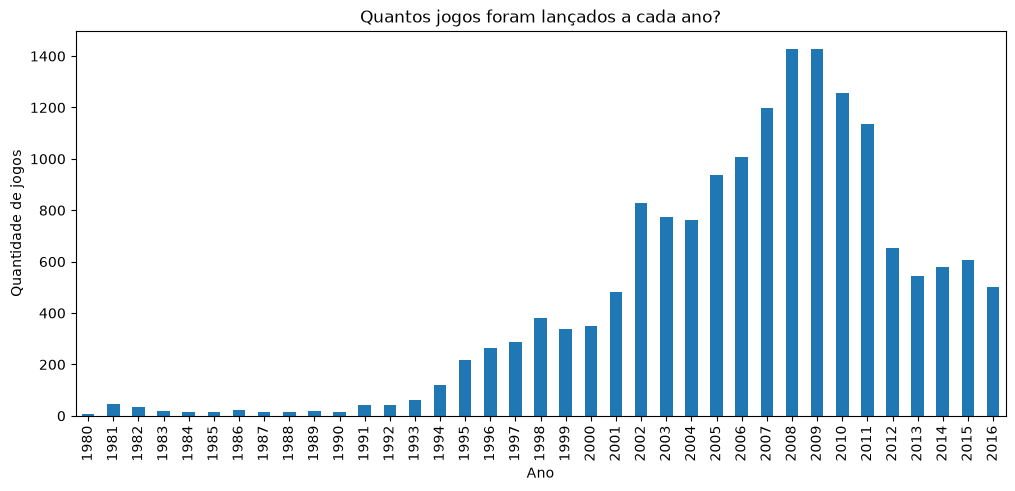

In [22]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12,5))
games_per_year.plot(kind='bar')
plt.title('Quantos jogos foram lançados a cada ano?')
plt.xlabel('Ano')
plt.ylabel('Quantidade de jogos')
plt.show()

##### **Considerações sobre a distribuição de lançamentos por ano**
Os lançamentos vão de 1980 a 2016, ou seja, 37 anos com jogos sendo lançados. O ano de 1980 foi o de menor número de lançamentos (9 jogos) e os anos de 2008 e 2009 como os maiores número de lançamento (1427). Ao longo dos anos tivemos uma grande variabilidade de quantidade de lançamentos, como anos de muito lançamento e outros poucos.

A distribuição dos lançamentos é assimétrica: temos um grupo de anos antigos com pouquíssimos lançamentos (25% anos tiveram 36 jogos lançados ou menos); e um grupo de anos mais recentes com muitos mais lançamentos. Nem todos os períodos são igualmente significativos e quando observamos o gráfico, distinguimos 3 fases: crescimento (1994–2001), pico (2002–2011) e queda acentuada (2012–2016). 


### 3.2 O "ciclo de vida" das plataformas de jogos
Agora, o objetivo é analisar como as vendas variaram entre as plataformas, identificando o "ciclo de vida" das plataformas. 
Primeiro, identificarei as plataformas com maiores vendas:
 1. Preparei tabela com as vendas totais
 2. Selecionei as 6 plataformas com maiores vendas
 3. Contrui uma distribuição com base nos dados para cada ano.

Depois, vou examinar quais as plataformas que costumavam ser populares, mas que agora não têm vendas.

<StringArray>
[ 'Wii',  'NES',   'GB',   'DS', 'X360',  'PS3',  'PS2', 'SNES',  'GBA',
  'PS4',  '3DS',  'N64',   'PS',   'XB',   'PC', '2600',  'PSP', 'XOne',
 'WiiU',   'GC',  'GEN',   'DC',  'PSV',  'SAT',  'SCD',   'WS',   'NG',
 'TG16',  '3DO',   'GG', 'PCFX']
Length: 31, dtype: str
platform
PS2     1255.77
X360     971.42
PS3      939.64
Wii      907.51
DS       806.12
PS       730.86
GBA      317.85
PS4      314.14
PSP      294.05
PC       259.52
Name: total_sales, dtype: float64


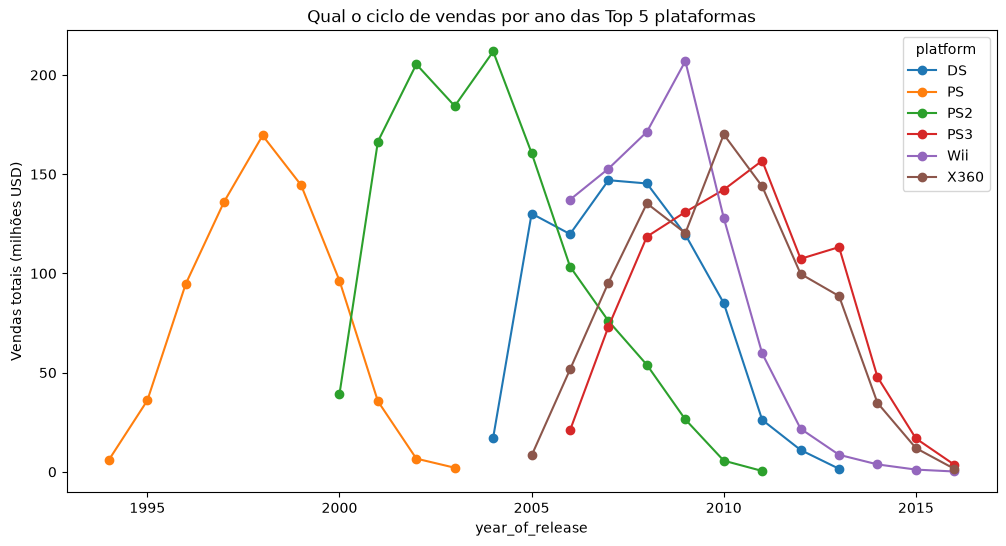

In [23]:
##1. Agrupando os dados por plataforma e somando as vendas totais
print(games['platform'].unique())
sales_by_platform = games.groupby('platform')['total_sales'].sum().sort_values(ascending=False)
 # Exibe as plataformas únicas

print(sales_by_platform.head(10))
top_platforms = sales_by_platform.head(6).index # pega as 6 plataformas com maior venda total (as 6 primeiras linhas do ranking acima)`.index` extrai apenas os nomes das plataformas

## 2. Criando uma tabela dinâmica (pivot table) para analisar a distribuição de vendas por ano para as plataformas top
pivot = games[games['platform'].isin(top_platforms)].pivot_table(index='year_of_release', 
                                                                 columns='platform', 
                                                                 values='total_sales', 
                                                                 aggfunc='sum')
#2. distribuição por ano para as plataformas top 5
# gráfico de linha (evolução temporal) 
pivot.plot(kind='line',style = 'o-', figsize=(12,6))
plt.title('Qual o ciclo de vendas por ano das Top 5 plataformas')
plt.ylabel('Vendas totais (milhões USD)')
plt.show()

In [24]:
ciclo_vida = games.groupby('platform')['year_of_release'].agg(['min', 'max'])
ciclo_vida['duracao'] = ciclo_vida['max'] - ciclo_vida['min']
ciclo_vida['duracao'].describe()

count        31.0
mean          7.0
std      5.899152
min           0.0
25%           3.0
50%           6.0
75%          10.0
max          31.0
Name: duracao, dtype: Float64

**Considerações sobre ciclo das plataformas:**


Selecionei as seis plataformas que tiveram os maiores valores total de vendas, como as mais populares. O corte foi com base no valor do total de vendas da 7ª colocada que representava menos da metade do valor total da 6ª (6ª PS = 730,86 USD x 7ª GBA = 317,85). Essas plataformas com maiores vendas são as plataformas que surgiram durante a fase de picos de lançamentos, entre 2002 e 2011. 

A maioria das plataformas, provavelmente tiveram seu maior sucesso de vendas nos primeiros anos de lançamentos, mas o pico de vendas diminuía em um ou dois anos. Muitas vezes essas reduções de vendas eram em períodos que outra plataforma era lançada.  De acordo com o gráfico, Plataforma “Wii” foi única plataforma que apresentou, logo no início do lançamento, muitas vendas e em 3 anos atingiu o maior número de vendas. Esse sucesso inicial, pode ser um resultado das inovações que a plataforma trouxe em relação as demais como maior interatividade dos jogos. Porém, houve um declínio, possivelmente em decorrência de uma maior venda de jogos na plataforma PS3 eX360.
 


### 3.3 Definição de o período relevante para previsões de 2017
Neste momento, o objetivo é determinar qual período devo usar para construir um modelo para 2017. Para determinar qual para qual período deveria pegar dados, utilizei os seguintes critérios:

1.	Qual o tempo médio de vida de uma plataforma (ciclo geral)?
2.	Quanto tempo leva para as novas plataformas aparecerem e as antigas desaparecerem?
3.	Quais plataformas ainda estarão vendendo em 2017?

Considerei as minhas observações sobre as análises anteriores de lançamentos por ano e as plataformas com mais vendas.

**Gráfico da relação de plataformas recém lançadas e as líderes**

In [25]:
# Confirmar quais plataformas tiveram primeiro lançamento em 2011 ou depois
primeiro_lancamento = games.groupby('platform')['year_of_release'].min()
plataformas_novas = primeiro_lancamento[primeiro_lancamento >= 2011].index.tolist()
print(plataformas_novas)

['3DS', 'PS4', 'PSV', 'WiiU', 'XOne']


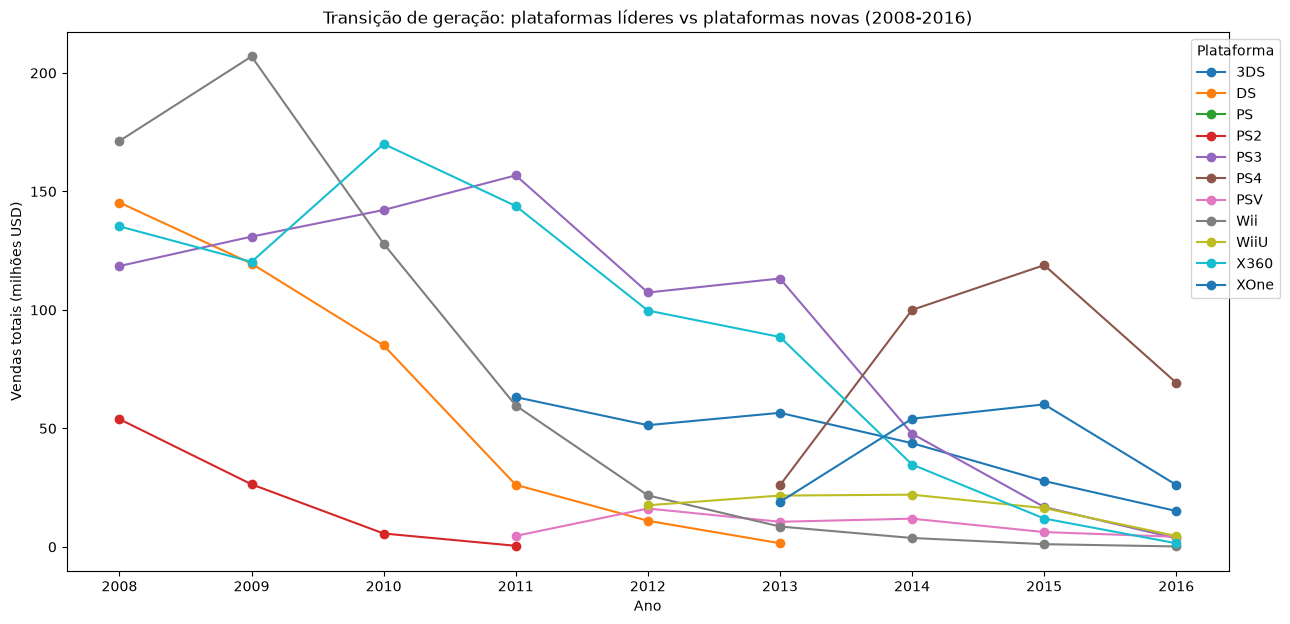

In [26]:

# Ver a evolução das 6 líderes + as novas gerações, ano a ano
### Plataformas líderes em vendas totais (histórico completo)
plataformas_lideres = ['PS2', 'X360', 'Wii', 'PS3', 'DS', 'PS']

# Plataformas novas: primeiro lançamento em 2011 ou depois (candidatas a estarem ativas em 2017)
primeiro_lancamento = games.groupby('platform')['year_of_release'].min()
plataformas_novas = primeiro_lancamento[primeiro_lancamento >= 2011].index.tolist()

# Unir as duas listas para visualizar a transição
plataformas_chave = list(set(plataformas_lideres + plataformas_novas))

pivot_transicao = games[games['platform'].isin(plataformas_chave)].pivot_table(
    index='year_of_release', columns='platform', values='total_sales', aggfunc='sum'
)

pivot_transicao.loc[2008:2016].plot(kind='line', marker='o', figsize=(15,7))
plt.title('Transição de geração: plataformas líderes vs plataformas novas (2008-2016)')
plt.xlabel('Ano')
plt.ylabel('Vendas totais (milhões USD)')
plt.legend(title='Plataforma', bbox_to_anchor=(1.05, 1))
plt.show()

**Definição do período de dados:**
O gráfico de transição confirma que 2013 é o ano em que a nova geração de consoles (PS4, XOne, WiiU) entra no mercado, coexistindo brevemente com a geração anterior (PS3, X360, Wii), que já está em declínio acentuado. A partir de 2014, a nova geração assume a liderança de vendas, e as plataformas anteriores praticamente desaparecem até 2016. 

Assim, considerando que:
(1) as plataformas líderes de vendas surgiram durante a fase de pico de lançamentos (2002–2011), 
(2) cada plataforma apresenta um ciclo de vida curto (em média 6 a 7 anos), com pico de vendas concentrado em 1 a 3 anos após o lançamento,
(3) o gráfico de transição mostra que as plataformas da geração anterior (PS3, X360, Wii) começam a perder espaço para a nova geração (PS4, XOne, WiiU) em 2014.

Defini que, os dados a partir de 2013 representam melhor o cenário de mercado relevante para a construção do modelo de 2017. Dados anteriores a esse período refletem gerações de consoles já obsoletas, cuja inclusão adicionaria ruído em vez de sinal útil à análise.


In [27]:
# Preprar tabela com os dados recentes (após 2013) para análise de tendências
ANO_DEFINIDO = 2013
games_recent = games[games['year_of_release'] >= ANO_DEFINIDO]

print(f'Registros no período selecionado: {games_recent.shape[0]} de {games.shape[0]} totais')
print(f'Plataformas ativas no período: {games_recent["platform"].nunique()}')
games_recent.head()

Registros no período selecionado: 2233 de 16712 totais
Plataformas ativas no período: 11


,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating,platform_launch_year,total_sales
16,Grand Theft Auto V,PS3,2013,Action,7.02,9.09,0.98,3.96,97.0,8.2,M,2006,21.05
23,Grand Theft Auto V,X360,2013,Action,9.66,5.14,0.06,1.41,97.0,8.1,M,2005,16.27
31,Call of Duty: Black Ops 3,PS4,2015,Shooter,6.03,5.86,0.36,2.38,NaN,NaN,Unknown,2013,14.63
33,Pokemon X/Pokemon Y,3DS,2013,Role-Playing,5.28,4.19,4.35,0.78,NaN,NaN,Unknown,2011,14.60
42,Grand Theft Auto V,PS4,2014,Action,3.96,6.31,0.38,1.97,97.0,8.3,M,2013,12.62


### 3.4 Quais plataformas são potencialmente lucrativas?

Como o novo conjuntode dados (2013-2016), vamos investigar quais plataformas são potencialmente lucrativas. Para isso, tentarei responde as seguintes perguntas, usando tabelas agrupadas e gráfico:
- Quais plataformas estão liderando em vendas?
- Quais estão crescendo ou diminuindo?

platform           3DS    DS     PC     PS3     PS4   PSP    PSV   Wii   WiiU  \
year_of_release                                                                 
2013             56.57  1.54  12.38  113.25   25.99  3.14  10.59  8.59  21.65   
2014             43.76   NaN  13.28   47.76  100.00  0.24  11.90  3.75  22.03   
2015             27.78   NaN   8.52   16.82  118.90  0.12   6.25  1.14  16.35   
2016             15.14   NaN   5.25    3.60   69.25   NaN   4.25  0.18   4.60   

platform          X360   XOne  
year_of_release                
2013             88.58  18.96  
2014             34.74  54.07  
2015             11.96  60.14  
2016              1.52  26.15  


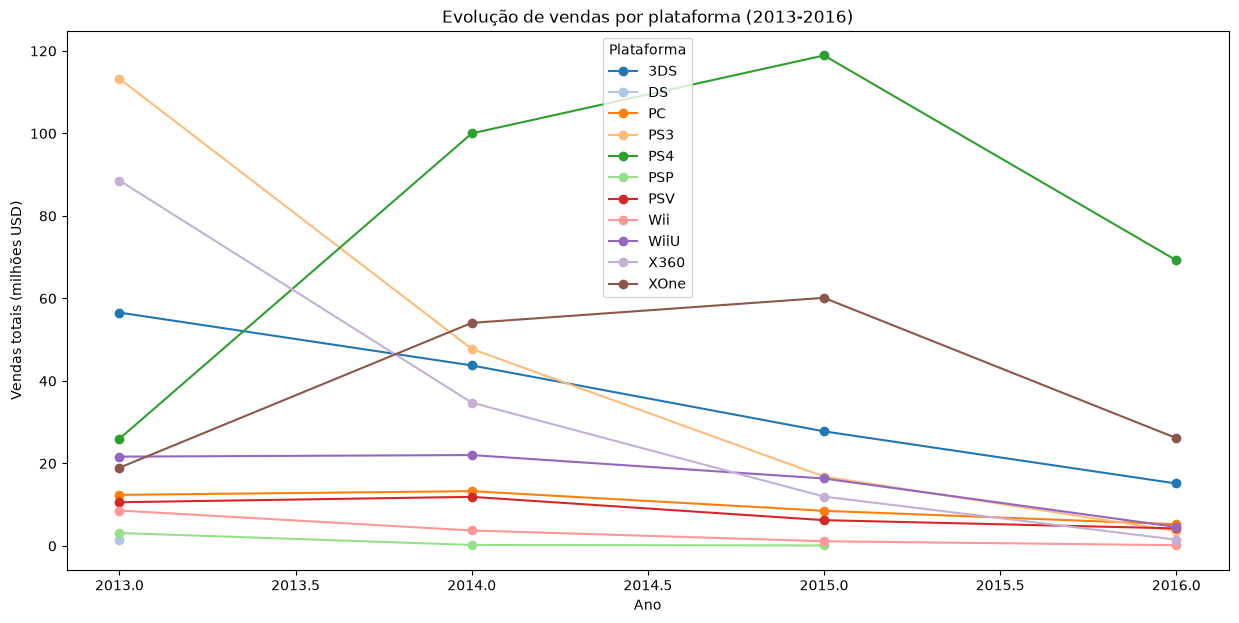

In [28]:
# Construindo a evolução de vendas por plataforma no período recente (após 2013)
plataformas_lideres = games_recent.pivot_table(index='year_of_release', 
                                               columns='platform', 
                                               values='total_sales', 
                                               aggfunc='sum')
print(plataformas_lideres.head())

import matplotlib.pyplot as plt

# Paleta com 11 cores distintas (uma por plataforma)
cores = plt.cm.tab20(range(len(plataformas_lideres.columns)))
plataformas_lideres.plot(kind='line', style='o-', figsize=(15,7), color=cores)
plt.title('Evolução de vendas por plataforma (2013-2016)')
plt.xlabel('Ano')
plt.ylabel('Vendas totais (milhões USD)')
plt.legend(title='Plataforma')
plt.show()

**Quais plataformas estão liderando em vendas? Quais estão crescendo ou diminuindo?**

As plataformas PS3, X360, apresentam uma clara tendência de declínio, a partir de 2013, enquanto as plataformas PS4 e XOne apresentam um aumento. XOne se mantém-se relativamente estável entre 2014 e 2016, já PS4 tem um crescimento a partir de 2013, mas mesmo com uma queda de vendas em 2016, ainda é a plataforma com maior venda. As demais iniciaram com baixas vendas seguem próximas de zero, com pouca relevância para a previsão de campanha.

### 3.5 Como são as vendas entre plataformas?
Pra investigar como é a distribuição das vendas globais de todos os jogos entre as plataformas, vou elabora um diagrama de caixa (boxplot). Com isso identificarei se há diferenças nas vendas entre plataformas e jogos.

             sum      mean  median       std  count       var
platform                                                     
X360      136.80  0.735484   0.265  1.663275    186  2.766484
XOne      159.32  0.645020   0.220  1.036139    247  1.073584
PS4       314.14  0.801378   0.200  1.609456    392  2.590350
WiiU       64.63  0.562000   0.200  1.038778    115  1.079060
Wii        13.66  0.593913   0.180  0.915432     23  0.838016
DS          1.54  0.192500   0.150  0.172026      8  0.029593
PS3       181.43  0.525884   0.150  1.451939    345  2.108128
3DS       143.25  0.472772   0.090  1.381347    303  1.908119
PC         39.43  0.208624   0.080  0.352304    189  0.124118
PSV        32.99  0.092151   0.040  0.153816    358  0.023660
PSP         3.50  0.052239   0.020  0.059768     67  0.003572


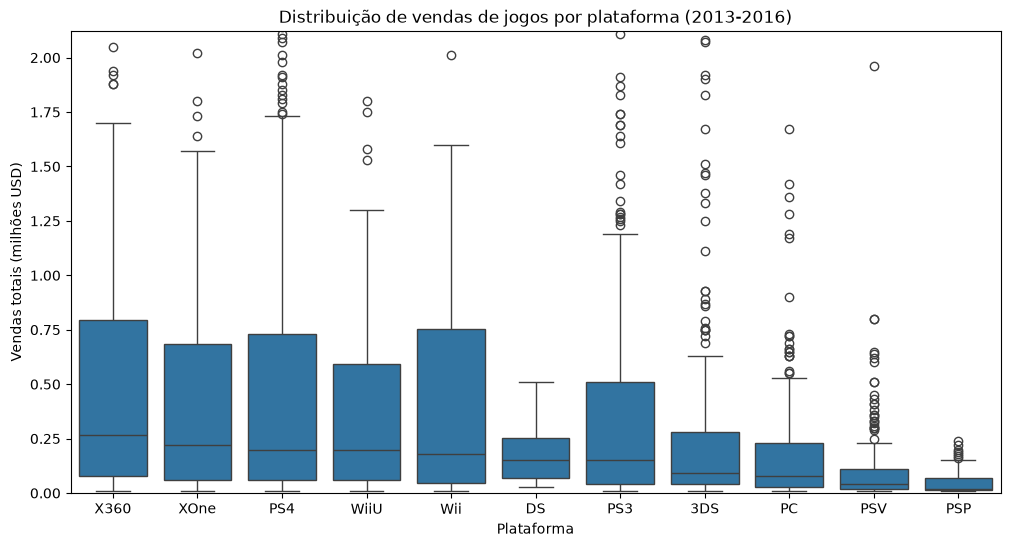

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

resumo_plataformas = games_recent.groupby('platform')['total_sales'].agg(['sum', 'mean', 'median', 'std', 'count',"var"]).sort_values('median', ascending=False)#ordena as plataformas pelo valor da mediana (50%)
print(resumo_plataformas)
#
plt.figure(figsize=(12,6))
sns.boxplot(data=games_recent, x='platform', y='total_sales',order=resumo_plataformas.index)
plt.title('Distribuição de vendas de jogos por plataforma (2013-2016)')
plt.xlabel('Plataforma')
plt.ylabel('Vendas totais (milhões USD)')
plt.ylim(0, games_recent['total_sales'].quantile(0.95))  # opcional, para reduzir efeito de outliers
plt.show()

**Observações sobre as vendas do período entre 2013 e 2016**

Analisando as distribuições das vendas entre as plataformas, é possível perceber que  as vendas tendem a ser similares entre as plataformas, não diferenças entre as médias para a maiorias das plataformas. Para as plataformas PC, DS, PSV, PSP a média de vendas é baixa e como já vimos nas análises anteriores a venda é estável ao longo dos anos.

Porém há presença de muitos valores atípicos de vendas, para todas as plataformas. Em todas as plataformas, os valores médios são maiores que a mediana, o que indica distribuição fortemente assimétrica à direita (right-skewed). Isso pode ser um relexo do comportamento esperado quando a maioria dos jogos vende pouco, e uma minoria de "hits" vende muito mais, puxando a média para cima e aparecendo como outliers no boxplot.

Quando investigamos a relação entre mediana e a média de vendas por plataforma, há uma discrepância em quase todos os casos, confirmando a forte assimetria da distribuição. Pela mediana, X360, XOne e WiiU apresentam o desempenho "típico" mais consistente entre seus jogos, enquanto PS4, com as maiores médias, tem uma mediana relativamente modesta. Isso indica que seu alto desempenho médio na plataforma é impulsionado por poucos títulos de grande sucesso, não pela maioria do catálogo. O caso mais extremo é o 3DS, cuja média (0.47) é cerca de cinco vezes maior que sua mediana (0.09), sugerindo forte dependência de poucos títulos-chave (provavelmente franquias consolidadas). PSP e PSV apresentam tanto médias quanto medianas baixas, indicando desempenho de vendas fraco e mais uniforme (sem grandes hits isolados).

### 3.6 Correlação entre avaliações de críticos e usuários com as vendas
Neste momento da análise, examinarei como as avaliações de usuários e profissionais afetam as vendas de duas das plataformas populares: PS4 e X360. Para isso vou construir um gráfico de dispersão e calcule a correlação entre avaliações e vendas

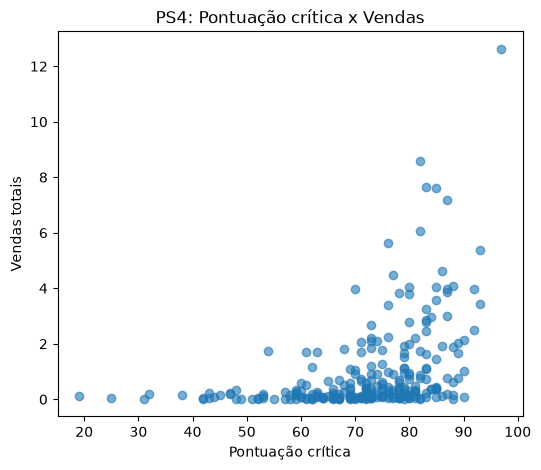

PS4 - Correlação Critic Score x Vendas: 0.407 (n=252)


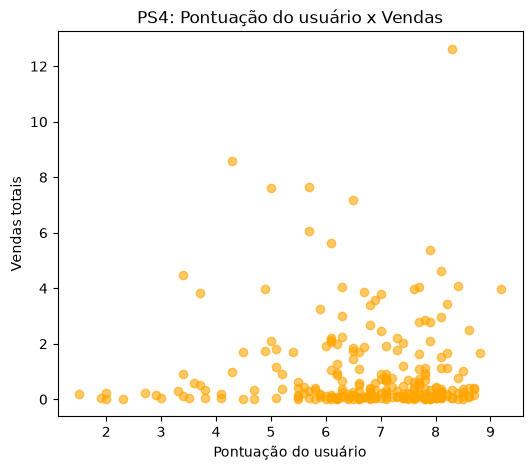

PS4 - Correlação User Score x Vendas: -0.032 (n=257)
--------------------------------------------------


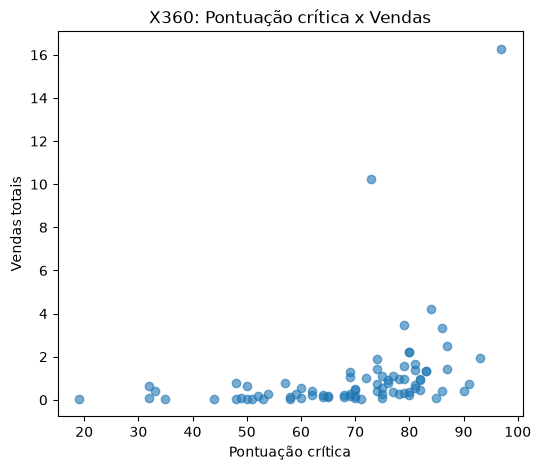

X360 - Correlação Critic Score x Vendas: 0.350 (n=81)


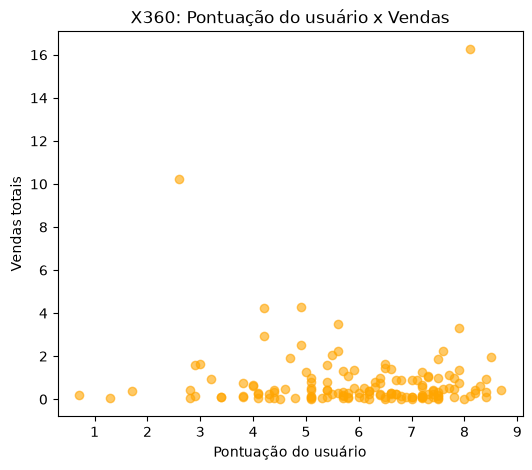

X360 - Correlação User Score x Vendas: -0.012 (n=143)
--------------------------------------------------


In [30]:
plataformas_analise = ['PS4', 'X360']

for plataforma in plataformas_analise:
    dados_plataforma = games_recent[games_recent['platform'] == plataforma]
    
    # --- Critic Score ---
    dados_critic = dados_plataforma[['critic_score', 'total_sales']].dropna()
    
    plt.figure(figsize=(6,5))
    plt.scatter(dados_critic['critic_score'], dados_critic['total_sales'], alpha=0.6)
    plt.xlabel('Pontuação crítica')
    plt.ylabel('Vendas totais')
    plt.title(f'{plataforma}: Pontuação crítica x Vendas')
    plt.show()
    
    corr_critic = dados_critic['critic_score'].corr(dados_critic['total_sales'])
    print(f'{plataforma} - Correlação Critic Score x Vendas: {corr_critic:.3f} (n={len(dados_critic)})')
    
    # --- User Score ---
    dados_user = dados_plataforma[['user_score', 'total_sales']].dropna()
    
    plt.figure(figsize=(6,5))
    plt.scatter(dados_user['user_score'], dados_user['total_sales'], alpha=0.6, color='orange')
    plt.xlabel('Pontuação do usuário')
    plt.ylabel('Vendas totais')
    plt.title(f'{plataforma}: Pontuação do usuário x Vendas')
    plt.show()
    
    corr_user = dados_user['user_score'].corr(dados_user['total_sales'])
    print(f'{plataforma} - Correlação User Score x Vendas: {corr_user:.3f} (n={len(dados_user)})')
    
    print('-' * 50)

**Qual a relação entre as pontuações de criticos e usuários e o total de vendas?**

Em relação as pontuações de críticos, para as duas plataforma houve uma tendência positiva, mas moderada, como as vendas, (PS4: 0,41;X360: 0,35). Apesar de não ser uma relação forte pode indicar que jogos mais bem avaliados por críticos profissionais tendem, em alguma medida, a vender mais.
Em relação as pontuações do usuários, a correlação não foram relevantes (PSA4:-0,032;X360:-0,011). Essa falta de correlação pode indicar que a nota dada pelos jogadores comuns não parece se relacionar com o volume de vendas do jogo. Algumas hipótese possíveis:
- Jogos "blockbuster" costumam vender muito independente da nota dos usuários.
- A nota da crítica geralmente sai antes ou no lançamento, podendo influenciar a decisão de compra inicial, enquanto a nota de usuários é formada depois da compra
- Muitos jogos são lançados para varias plataformas e acaba dividindo as vendas.

#### 3.7 Comparação de vendas do mesmo jogo em outras plataformas
Como apresentado anteriormente, muito jogos são lançados em diferente plataformas. Isso é uma característica importante para se examinar, pois influencia na compra de jogos. Para tal finalidade, vou:
 1. Avaliar quantos jogos aparacem em mais de uma plataforma
 2. Filtra e gerar uma nova tabela 
 3.  visualizar a distribuição de vendas por plataforma, só para jogos multiplataforma
 4. Comparar os jogos com maior venda total (soma de todas as plataformas)

In [31]:
# Ver quantos jogos aparecem em mais de uma plataforma dentro do período analisado
jogos_multiplataforma = games_recent.groupby('name')['platform'].nunique()
jogos_multiplataforma = jogos_multiplataforma[jogos_multiplataforma > 1]

print(f'{len(jogos_multiplataforma)} jogos aparecem em mais de uma plataforma no período recente')
print(f'Isso representa {len(jogos_multiplataforma) / games_recent["name"].nunique() * 100:.1f}% dos jogos')

473 jogos aparecem em mais de uma plataforma no período recente
Isso representa 37.5% dos jogos


          count      mean       std   min     25%    50%     75%    max
platform                                                               
X360      180.0  0.747111  1.686678  0.01  0.0800  0.270  0.8175  16.27
PS4       316.0  0.884335  1.714402  0.01  0.0775  0.265  0.8650  14.63
XOne      224.0  0.603080  1.006972  0.01  0.0575  0.220  0.6450   7.39
PS3       277.0  0.594621  1.590227  0.01  0.0600  0.200  0.5800  21.05
Wii        22.0  0.618636  0.929082  0.01  0.0450  0.180  0.8525   3.58
DS          8.0  0.192500  0.172026  0.03  0.0675  0.150  0.2525   0.51
3DS        62.0  0.330484  0.964556  0.01  0.0625  0.125  0.2775   7.55
WiiU       70.0  0.321286  0.617247  0.01  0.0500  0.120  0.4600   4.87
PC        130.0  0.208231  0.274840  0.01  0.0325  0.095  0.2300   1.36
PSV       140.0  0.134643  0.198865  0.01  0.0400  0.090  0.1425   1.96
PSP        14.0  0.102857  0.083705  0.01  0.0225  0.085  0.1775   0.24


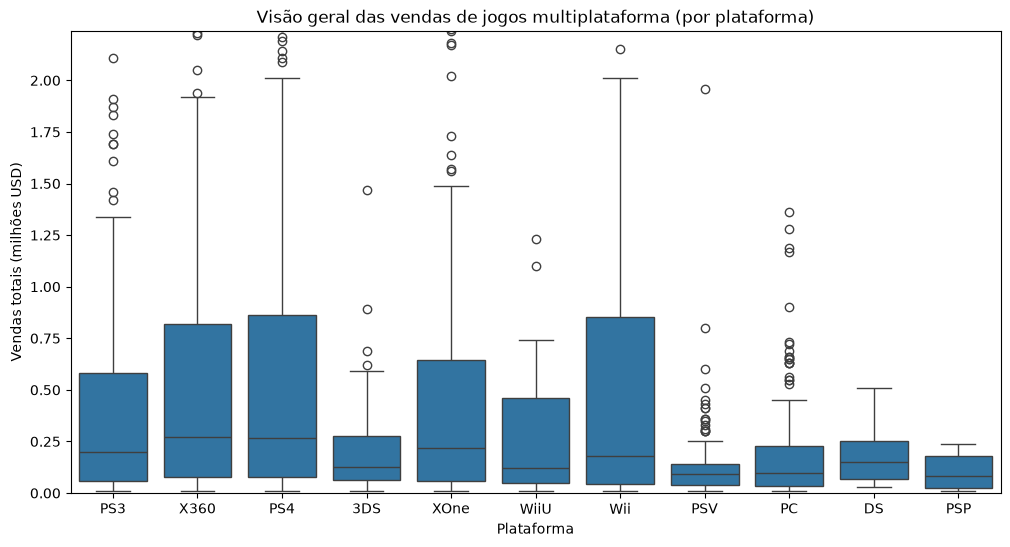

In [32]:
# Filtrar apenas os jogos que aparecem em mais de uma plataforma
nomes_multiplataforma = jogos_multiplataforma.index
dados_multi = games_recent[games_recent['name'].isin(nomes_multiplataforma)]

print(dados_multi.groupby('platform')['total_sales'].describe().sort_values('50%', ascending=False))#ordena as plataformas pelo valor da mediana (50%)

#Visão geral: distribuição de vendas por plataforma, só para jogos multiplataforma
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(12,6))
sns.boxplot(data=dados_multi, x='platform', y='total_sales')
plt.ylim(0, dados_multi['total_sales'].quantile(0.95))
plt.title('Visão geral das vendas de jogos multiplataforma (por plataforma)')
plt.xlabel('Plataforma')
plt.ylabel('Vendas totais (milhões USD)')
plt.show()

Top 10 jogos multiplataforma por venda total combinada:
Index(['Grand Theft Auto V', 'Call of Duty: Ghosts',
       'Call of Duty: Black Ops 3', 'Minecraft',
       'Call of Duty: Advanced Warfare', 'FIFA 15', 'FIFA 14', 'FIFA 16',
       'Battlefield 4', 'Assassin's Creed IV: Black Flag'],
      dtype='str', name='name')
platform                          3DS    PC    PS3    PS4   PSP   PSV   Wii  \
name                                                                          
Assassin's Creed IV: Black Flag   NaN  0.65   3.71   2.86   NaN   NaN   NaN   
Battlefield 4                     NaN  1.36   3.49   3.58   NaN   NaN   NaN   
Call of Duty: Advanced Warfare    NaN  0.41   4.36   7.66   NaN   NaN   NaN   
Call of Duty: Black Ops 3         NaN  0.26   1.69  14.63   NaN   NaN   NaN   
Call of Duty: Ghosts              NaN  0.69   9.36   3.83   NaN   NaN   NaN   
FIFA 14                          0.23  0.40   6.46   3.01  0.19  0.41  0.38   
FIFA 15                          0.46  0.29 

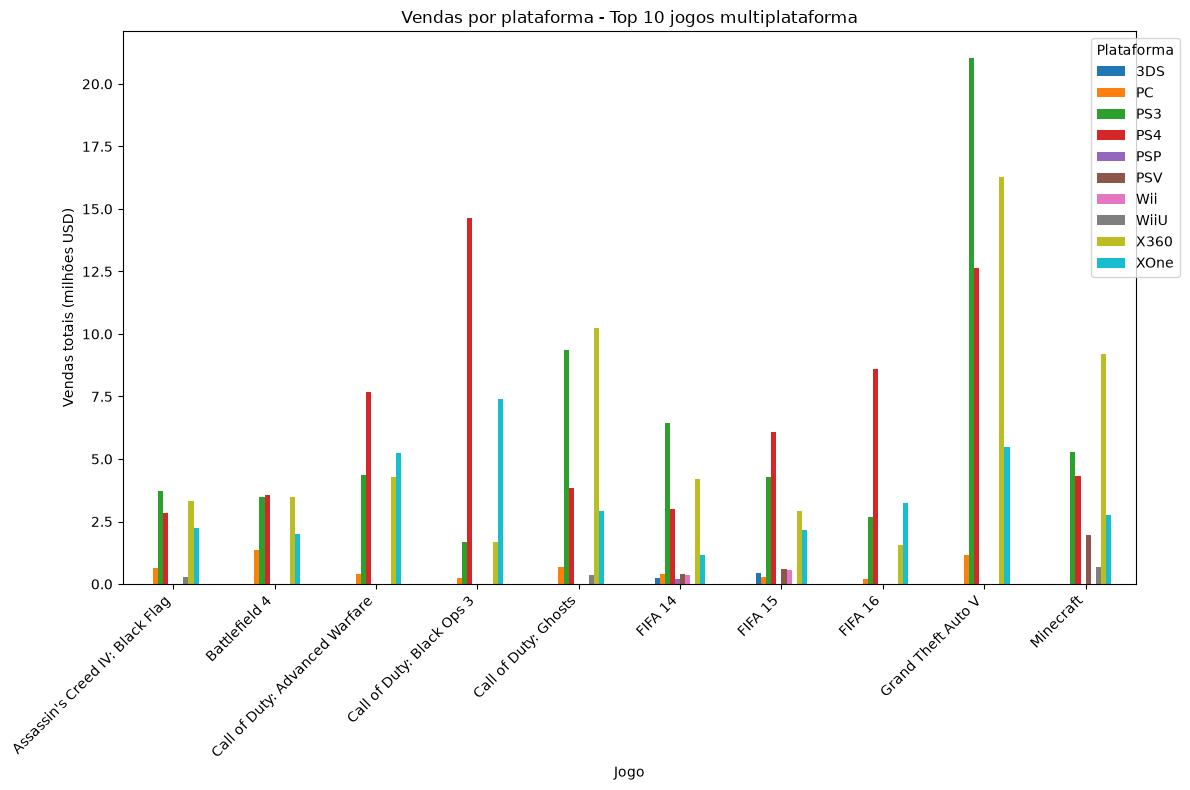

platform                          3DS    PC    PS3    PS4   PSP   PSV   Wii  \
name                                                                          
Assassin's Creed IV: Black Flag   NaN  0.65   3.71   2.86   NaN   NaN   NaN   
Battlefield 4                     NaN  1.36   3.49   3.58   NaN   NaN   NaN   
Call of Duty: Advanced Warfare    NaN  0.41   4.36   7.66   NaN   NaN   NaN   
Call of Duty: Black Ops 3         NaN  0.26   1.69  14.63   NaN   NaN   NaN   
Call of Duty: Ghosts              NaN  0.69   9.36   3.83   NaN   NaN   NaN   
FIFA 14                          0.23  0.40   6.46   3.01  0.19  0.41  0.38   
FIFA 15                          0.46  0.29   4.28   6.08   NaN  0.60  0.56   
FIFA 16                           NaN  0.20   2.70   8.58   NaN   NaN   NaN   
Grand Theft Auto V                NaN  1.17  21.05  12.62   NaN   NaN   NaN   
Minecraft                         NaN   NaN   5.27   4.32   NaN  1.96   NaN   

platform                         WiiU   X360  XOne 

In [33]:
#Visão específica: comparar os jogos com maior venda total
# Top 10 jogos multiplataforma por venda total combinada
top_jogos = dados_multi.groupby('name')['total_sales'].sum().sort_values(ascending=False).head(10).index
print(f'Top 10 jogos multiplataforma por venda total combinada:\n{top_jogos}')

# Pivotar: linha = jogo, coluna = plataforma, valor = venda
comparacao_jogos = dados_multi[dados_multi['name'].isin(top_jogos)].pivot_table(index='name', 
                                                                                columns='platform', 
                                                                                values='total_sales', 
                                                                                aggfunc='sum'
)

print(comparacao_jogos)
comparacao_jogos.plot(kind='bar', figsize=(12,8))
plt.title('Vendas por plataforma - Top 10 jogos multiplataforma')
plt.xlabel('Jogo')
plt.ylabel('Vendas totais (milhões USD)')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Plataforma', bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

print(comparacao_jogos)

**Jogos  multiplataformas**

Entre 2013 e 2016, cerca 473 jogos aparecem em mais de uma plataforma, ou seja, **37%** dos jogos vendidos. A distribuição das vendas entre as plataformas desses jogos também mostra o padrão de transição entre geração de plataformas. Mesmo em jogos vendidos em multiplataformas, PS4 e X360 novamente, apresentam as maiores médias e medianas de vendas, o que mostra o maior alcance comercial mesmo quando o mesmo título está disponível em outras plataformas. 

Ao examinar os 10 jogos multiplataformas mais vendidos, verifica-se que jogos lançados por volta de 2013, como Grand Theft Auto V e Call of Duty: Ghosts, ainda venderam mais na versão PS3 do que na versão PS4. Isso pode ser um reflexo de poucos usuários de uma versão recém lançada. Em títulos mais novos, como Call of Duty: Black Ops 3 (2015) e FIFA 16, as versões para PS4 são mais populares do que anterior. Esses padrões indicam que a plataforma PS4 é uma das mais populares desse período.

### 3.8 Distribuição por gênero
Após investigar a relação de vendas entre plataformas, relação entre avaliações e vendas  e as vendas de jogos multiplataformas, vamos examinar distribuição de vendas por gênero. O objetivo é identificar quais categorias tendem a ser mais ou menos lucrativas.
Seguiremos os passos abaixo:
1. Criar uma tabela as vendas por gênero
2. Calcular as Estatísticas descritivas por gênero (média, mediana, dispersão)
3. Visualizar a distribuição das vendas em um diagram de caixa
4. Comparar volume de lançamentos vs vendas (ajuda a diferenciar "gênero mais lucrativo" com "gênero com mais jogos lançados")

genre
Action          321.87
Shooter         232.98
Sports          150.65
Role-Playing    145.89
Misc             62.82
Platform         42.63
Racing           39.89
Fighting         35.31
Adventure        23.64
Simulation       21.76
Strategy         10.08
Puzzle            3.17
Name: total_sales, dtype: float64


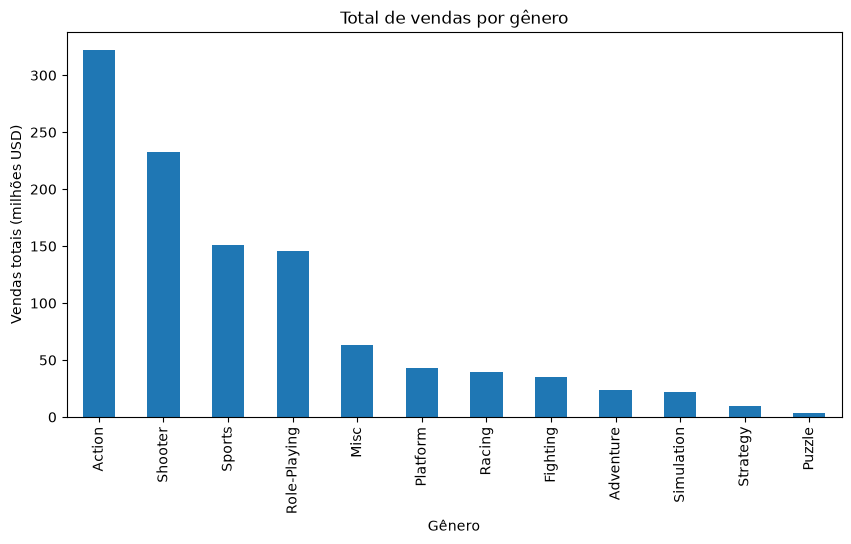

In [34]:
# Tabela de vendas totais por gênero no período recente
genero_vendas = games_recent.groupby('genre')['total_sales'].sum().sort_values(ascending=False)
print(genero_vendas)

plt.figure(figsize=(10,5))
genero_vendas.plot(kind='bar')
plt.title('Total de vendas por gênero')
plt.xlabel('Gênero')
plt.ylabel('Vendas totais (milhões USD)')
plt.show()

                 sum      mean  median       std  count       var
genre                                                            
Shooter       232.98  1.245882   0.450  2.014107    187  4.056627
Sports        150.65  0.703972   0.240  1.219237    214  1.486540
Platform       42.63  0.576081   0.225  0.806808     74  0.650939
Role-Playing  145.89  0.499623   0.125  1.353164    292  1.831052
Racing         39.89  0.469294   0.120  0.964101     85  0.929490
Fighting       35.31  0.441375   0.125  1.048883     80  1.100156
Action        321.87  0.420196   0.110  1.253909    766  1.572289
Misc           62.82  0.405290   0.100  1.007985    155  1.016033
Simulation     21.76  0.350968   0.100  0.849163     62  0.721078
Puzzle          3.17  0.186471   0.060  0.325172     17  0.105737
Strategy       10.08  0.180000   0.080  0.279441     56  0.078087
Adventure      23.64  0.096490   0.030  0.216445    245  0.046848


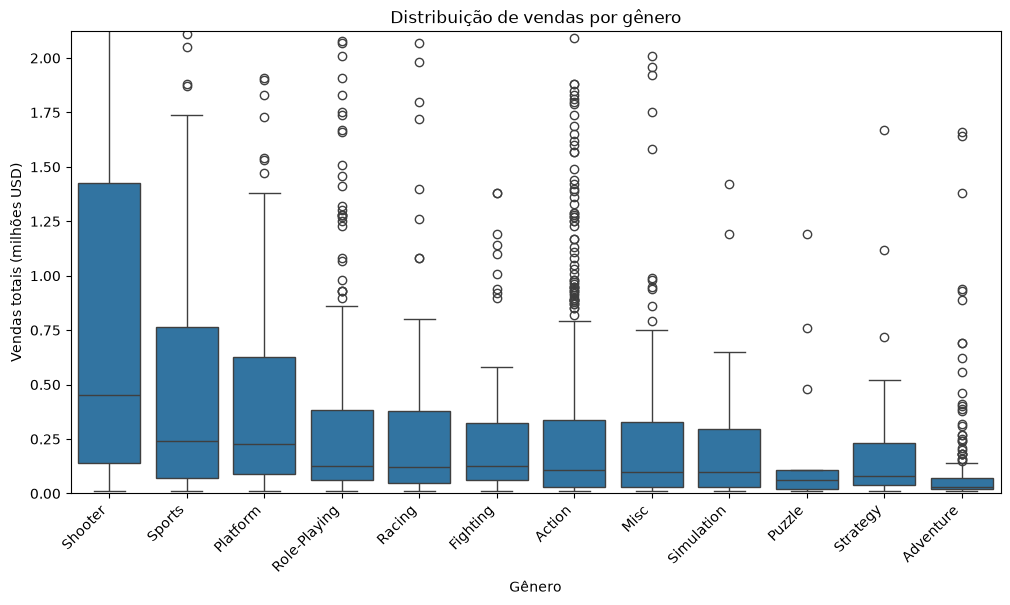

In [35]:
# Tabela resumo de vendas por gênero no período recente
genero_resumo = games_recent.groupby('genre')['total_sales'].agg(['sum', 'mean', 'median', 'std', 'count',"var"]).sort_values('mean', ascending=False)
print(genero_resumo)

plt.figure(figsize=(12,6))
sns.boxplot(data=games_recent, x='genre', y='total_sales', order=genero_resumo.index)# order=genero_resumo.index alinha a ordem do boxplot com a tabela de médias, facilitando comparar visual e numericamente.
plt.ylim(0, games_recent['total_sales'].quantile(0.95))
plt.xticks(rotation=45, ha='right')
plt.title('Distribuição de vendas por gênero')
plt.xlabel('Gênero')
plt.ylabel('Vendas totais (milhões USD)')
plt.show()

In [36]:
# Tabela de comparação: total de vendas, quantidade de jogos e venda média por jogo, por gênero
comparacao = games_recent.groupby('genre').agg(total_vendas=('total_sales', 'sum'),qtd_jogos=('name', 'count'))
comparacao['venda_media_por_jogo'] = comparacao['total_vendas'] / comparacao['qtd_jogos']
print(comparacao.sort_values('total_vendas', ascending=False))

              total_vendas  qtd_jogos  venda_media_por_jogo
genre                                                      
Action              321.87        766              0.420196
Shooter             232.98        187              1.245882
Sports              150.65        214              0.703972
Role-Playing        145.89        292              0.499623
Misc                 62.82        155              0.405290
Platform             42.63         74              0.576081
Racing               39.89         85              0.469294
Fighting             35.31         80              0.441375
Adventure            23.64        245              0.096490
Simulation           21.76         62              0.350968
Strategy             10.08         56              0.180000
Puzzle                3.17         17              0.186471


**Quais categorias tendem a ser mais ou menos lucrativas?** 


A distribuição de vendas entre os gêneros mostra a presença de valores atípicos (outliers),  como já observado na análise por plataforma. Na maioria dos gêneros, alguns poucos jogos vendem muito acima da média, gerando grande dispersão nos valores de vendas. 

Os gêneros "Shooter" e "Role-Playing" apresentam o maior desvio padrão relativo à própria média (2,0 e 1,35, respectivamente), indicando forte dependência de poucos títulos "blockbuster" que puxam o resultado geral para cima. A mediana bem mais baixa que a média nesses gêneros (0,45 e 0,13) confirma que a maioria dos jogos vende relativamente pouco, enquanto alguns títulos disparam. O gênero "Action" também apresenta desvio padrão relativamente alto (1,07), sugerindo que mesmo o gênero líder em volume de vendas não escapa dessa dependência de sucessos pontuais. Já o gênero "Adventure" apresenta o padrão oposto: o menor desvio padrão entre todos (0.19), indicando vendas mais uniformemente baixas, sem grandes sucessos isolados. 

Ao explorar o volume de lançamentos versus o desempenho médio por título, é possível distinguir volume de lançamentos de desempenho comercial individual. O gênero "Action" lidera em vendas totais (321,87 milhões), mas sua venda média por jogo é relativamente baixa (0,42) — resultado provavelmente do alto volume de lançamentos no período (766 jogos), e não de um desempenho individual superior. Já o gênero "Shooter" tem menos da metade dos lançamentos de Action (187 jogos), mas apresenta a maior venda média por título entre todos os gêneros (1.09), sendo o gênero mais lucrativo por jogo lançado. O gênero "Adventure" representa o caso oposto ao de Action: apesar do alto volume de lançamentos (245 jogos, o 3º maior), apresenta o pior desempenho médio entre todos os gêneros (0,09). Isso sugere um gênero com vendas pulverizadas entre muitos títulos de nicho, sem grandes sucessos comerciais que sustentem a média. 

Considerando essas comparações, evidencia-se não é possível generalizar "gêneros com vendas altas" apenas pelo total vendido. "Shooter" se destaca como o gênero de maior retorno por título, enquanto "Action" deve seu volume de vendas principalmente à quantidade de lançamentos, não ao desempenho individual de cada título. Esse padrão sugere que investir em "Shooter" ou "Role-Playing" pode representar maior risco (alta variabilidade de retorno), mas também maior potencial de ganho caso o título se torne um sucesso — enquanto gêneros como "Adventure" oferecem resultado mais previsível, porém consistentemente mais modesto.


## Etapa 4. Perfils dos usuários de cada região
O objetivo agora é investigar qual o perfil dos usuários de cada regão de vendas: União Europeia (UE), América do Norte(AN) e Japão(JP). Seguremos o seguinte passo a passo
1. Identificar as cinco plataformas principais de cada região.
2. Descreve as variações das suas quotas de mercado de região para região.
3. Identificar os cinco principais gêneros de jogos de cada região

**Quais as cinco principais plataformas para as regiões da União Europeia, América do Norte e Japão?**

In [37]:
# Análise das top 5 plataformas por região
regioes = {'AN': 'na_sales', 'UE': 'eu_sales', 'JP': 'jp_sales'}

top_plataformas_regiao = {}

for regiao, coluna in regioes.items():
    # Calcular a soma das vendas por plataforma na região específica
    vendas_plataforma = games_recent.groupby('platform')[coluna].sum().sort_values(ascending=False)
    top5 = vendas_plataforma.head(5)
    # calcular a participação percentual de cada plataforma no total vendido naquela região:
    quota = (top5 / games_recent[coluna].sum() * 100).round(2) 
    
    tabela = pd.DataFrame({'vendas': top5, 'quota_mercado_%': quota})
    top_plataformas_regiao[regiao] = tabela
    
    print(f'--- Top 5 plataformas - {regiao} ---')
    print(tabela)
    print()

--- Top 5 plataformas - AN ---
          vendas  quota_mercado_%
platform                         
PS4       108.74            24.84
XOne       93.12            21.27
X360       81.66            18.66
PS3        63.50            14.51
3DS        38.20             8.73

--- Top 5 plataformas - UE ---
          vendas  quota_mercado_%
platform                         
PS4       141.09            35.97
PS3        67.81            17.29
XOne       51.59            13.15
X360       42.52            10.84
3DS        30.96             7.89

--- Top 5 plataformas - JP ---
          vendas  quota_mercado_%
platform                         
3DS        67.81            48.17
PS3        23.35            16.59
PSV        18.59            13.21
PS4        15.96            11.34
WiiU       10.88             7.73



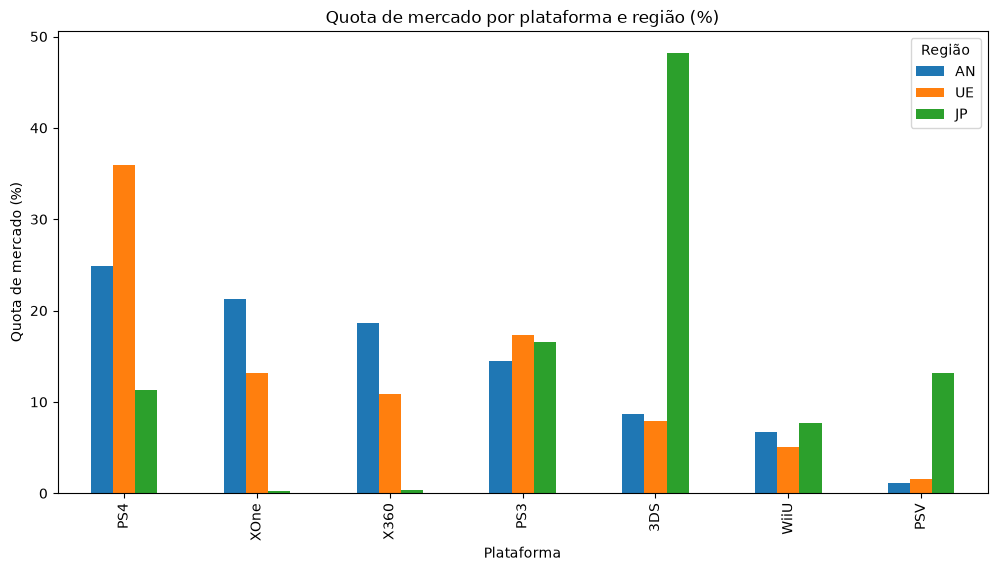

In [38]:
# Montar uma tabela única: linhas = plataforma, colunas = região, valores = quota de mercado
todas_plataformas_top = set()
for regiao in regioes:
    todas_plataformas_top.update(top_plataformas_regiao[regiao].index)

comparacao_quotas = pd.DataFrame(index=list(todas_plataformas_top))

for regiao, coluna in regioes.items():
    vendas_plataforma = games_recent.groupby('platform')[coluna].sum()
    quota_total = vendas_plataforma / games_recent[coluna].sum() * 100
    comparacao_quotas[regiao] = quota_total.reindex(comparacao_quotas.index)

comparacao_quotas = comparacao_quotas.sort_values('AN', ascending=False)

comparacao_quotas.plot(kind='bar', figsize=(12,6))
plt.title('Quota de mercado por plataforma e região (%)')
plt.xlabel('Plataforma')
plt.ylabel('Quota de mercado (%)')
plt.legend(title='Região')
plt.show()

**Quais os cinco principais gêneros de cada região?**

In [39]:
top_generos_regiao = {}

for regiao, coluna in regioes.items():
    vendas_genero = games_recent.groupby('genre')[coluna].sum().sort_values(ascending=False)
    top5 = vendas_genero.head(5)
    quota = (top5 / games_recent[coluna].sum() * 100).round(2)
    
    tabela = pd.DataFrame({'vendas': top5, 'quota_mercado_%': quota})
    top_generos_regiao[regiao] = tabela
    
    print(f'--- Top 5 gêneros - {regiao} ---')
    print(tabela)
    print()

--- Top 5 gêneros - AN ---
              vendas  quota_mercado_%
genre                                
Action        126.05            28.80
Shooter       109.74            25.07
Sports         65.27            14.91
Role-Playing   46.40            10.60
Misc           27.49             6.28

--- Top 5 gêneros - UE ---
              vendas  quota_mercado_%
genre                                
Action        118.13            30.12
Shooter        87.86            22.40
Sports         60.52            15.43
Role-Playing   36.97             9.43
Racing         20.19             5.15

--- Top 5 gêneros - JP ---
              vendas  quota_mercado_%
genre                                
Role-Playing   51.04            36.26
Action         40.49            28.76
Misc            9.20             6.54
Fighting        7.65             5.43
Shooter         6.61             4.70



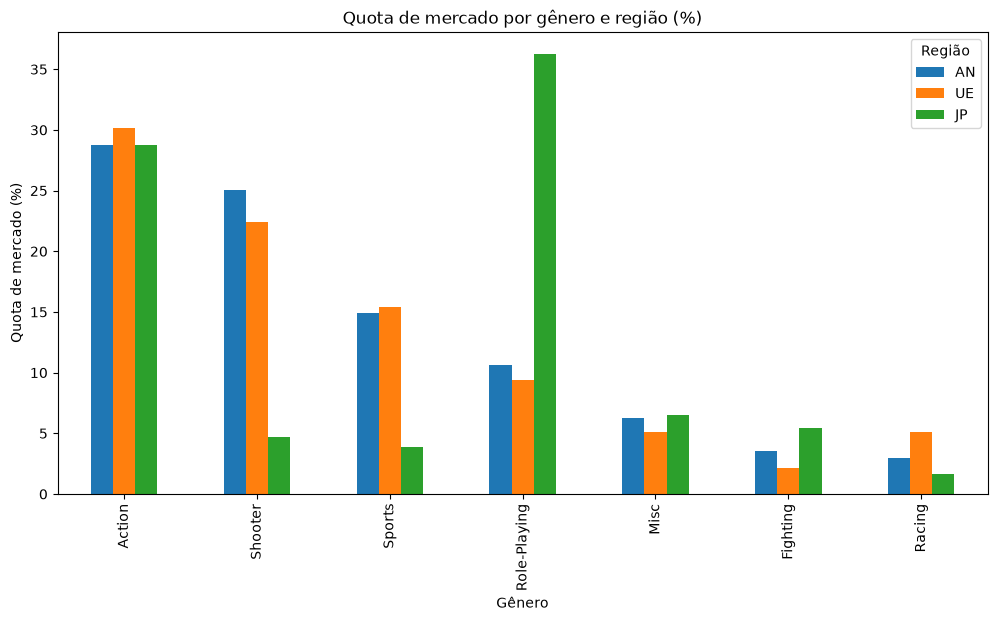

In [40]:
# Mesmo padrão de gráfico comparativo
todos_generos_top = set()
for regiao in regioes:
    todos_generos_top.update(top_generos_regiao[regiao].index)

comparacao_generos = pd.DataFrame(index=list(todos_generos_top))

for regiao, coluna in regioes.items():
    vendas_genero = games_recent.groupby('genre')[coluna].sum()
    quota_total = vendas_genero / games_recent[coluna].sum() * 100
    comparacao_generos[regiao] = quota_total.reindex(comparacao_generos.index)

comparacao_generos = comparacao_generos.sort_values('AN', ascending=False)

comparacao_generos.plot(kind='bar', figsize=(12,6))
plt.title('Quota de mercado por gênero e região (%)')
plt.xlabel('Gênero')
plt.ylabel('Quota de mercado (%)')
plt.legend(title='Região')
plt.show()

**As classificações do ESRB afetam as vendas em regiões individuais?**

In [41]:
efeito_rating_regiao = {}

for regiao, coluna in regioes.items():
    vendas_rating = games_recent.groupby('rating')[coluna].sum().sort_values(ascending=False)
    quota = (vendas_rating / games_recent[coluna].sum() * 100).round(2)
    
    tabela = pd.DataFrame({'vendas': vendas_rating, 'quota_mercado_%': quota})
    efeito_rating_regiao[regiao] = tabela
    
    print(f'--- Vendas por Rating ESRB - {regiao} ---')
    print(tabela)
    print()

--- Vendas por Rating ESRB - AN ---
         vendas  quota_mercado_%
rating                          
M        165.21            37.74
Unknown   89.42            20.43
E         79.05            18.06
E10+      54.24            12.39
T         49.79            11.38

--- Vendas por Rating ESRB - UE ---
         vendas  quota_mercado_%
rating                          
M        145.32            37.05
E         83.36            21.25
Unknown   78.91            20.12
E10+      42.69            10.88
T         41.95            10.70

--- Vendas por Rating ESRB - JP ---
         vendas  quota_mercado_%
rating                          
Unknown   85.05            60.41
T         20.59            14.63
E         15.14            10.75
M         14.11            10.02
E10+       5.89             4.18



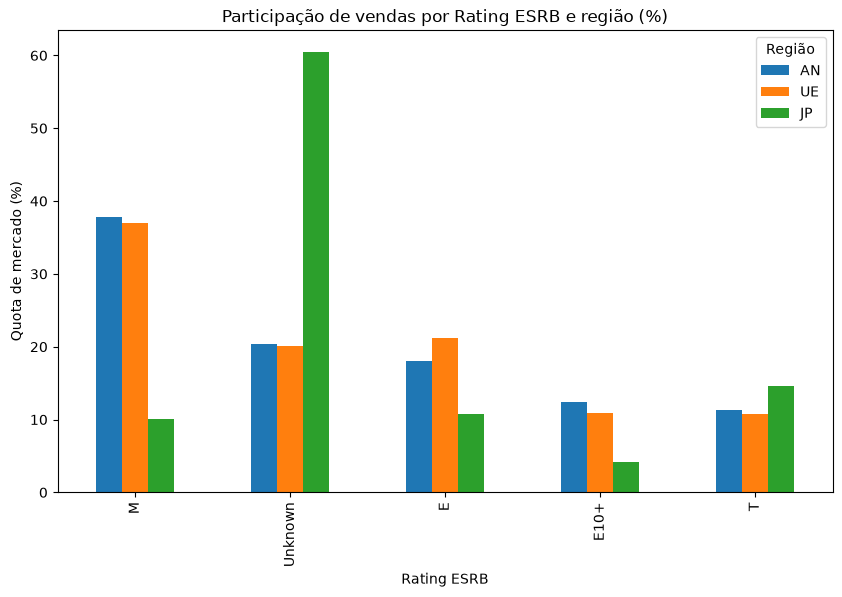

In [42]:
comparacao_rating = pd.DataFrame(index=games_recent['rating'].dropna().unique())

for regiao, coluna in regioes.items():
    vendas_rating = games_recent.groupby('rating')[coluna].sum()
    quota_total = vendas_rating / games_recent[coluna].sum() * 100
    comparacao_rating[regiao] = quota_total.reindex(comparacao_rating.index)

comparacao_rating = comparacao_rating.sort_values('AN', ascending=False)

comparacao_rating.plot(kind='bar', figsize=(10,6))
plt.title('Participação de vendas por Rating ESRB e região (%)')
plt.xlabel('Rating ESRB')
plt.ylabel('Quota de mercado (%)')
plt.legend(title='Região')
plt.show()

**Considerações sobre o perfil dos usuários para as regiões da União Europeia, América do Norte e Japão**

**Plataforma**

As plataformas preferidas variam entre as regiões, mas nas regiões da União Europeia e América do Norte apresenta um perfil de interesse parecido, enquanto no Japão o perfil já bem diferente.

União Europeia e América do Norte tem o mercado é dominado por consoles de mesa, com o PS4 na liderança em ambos (24.8% e 35.97%, respectivamente), seguido por concorrentes ocidentais (XOne, X360, PS3). Na Europa  a concentração de vendas do PS4 é ainda maior, quase 36% de quota, enquanto na América do norte é 25%.

Quando observamos o Japão, nos deparamos com um cenário em que o 3DS lidera com quase metade da quota de mercado (48.17%), enquanto o PS4 ocupa apenas a 4ª posição, com participação bem menor (11.34%) do que nos outros mercados. Essa diferença reflete a forte preferência do público japonês por plataformas portáteis, um padrão não observado nas outras.

**Gênero**

Quanto ao gênero preferidos das regiões, novamente o comportamento dos usuários da União Europeia, América do Norte são parecidos. Em ambos, á um domino de jogos de ação e "shooter", juntos, representam cerca de 54-56% do mercado, depois temos jogos de esporte ("Sports").

No Japão, jogos de ação também tem uma grande parcela de interesse, 28,8%, mas  a liderança é de jogos "Role-Playing" é o gênero líder (36.26%), muito à frente do que ocupa nos mercados ocidentais. Já o gênero "Shooter" (2º gênero mais forte em AN e UE) aparece apenas na última posição do top 5 japonês (4.70%). Essa diferença é consistente com a preferência japonesa por RPGs, um gênero historicamente forte na indústria local de jogos.

**CLassificação ESRB**

As análises a respeito da classificação ESRB apresenta uma limitação importante: uma parcela  grande das vendas japonesas (60.41%) está associada a jogos sem classificação ESRB ("Unknown"), proporção bem maior que em NA (20.43%) e EU (20.12%). Isso provavelmente é fruto uma limitação da próprio sistema de classificação que é uma classificação de origem norte-americana, e muitos jogos lançados  exclusivamente no mercado japonês podem não possuir essa classificação.

Com isso, se desconsiderarmos a categoria "Unknown", o rating M (Mature) é o mais vendido nas três regiões, mas com participação bem mais expressiva em América (37.74%) e Europa (37.05%) do que no Japão (10.02%), onde os ratings T e E têm participação relativamente maior. Essa diferença pode estar relacionada tanto a diferenças culturais de consumo quanto à já mencionada limitação dos dados  de classificação para o mercado japonês.

## Etapa 5. Teste de hipótese:
Construído o perfil dos usuários, agora vamos examinar sobre as diferenças entre as avaliações dos usuários entre algumas plataformas  e gêneros. Para verificar se há diferenças significativas nas médias vamos realizar teste **t de Student** para duas amostras independentes: ele testa se as médias de dois grupos diferentes são estatisticamente iguais(hipótese nula) ou diferentes(hipótese alternativa). Testaremos as seguinte hipóteses:
 - As classificações médias dos usuários das plataformas Xbox One e PC são as mesmas.
 - As classificações médias de usuários para os gêneros Action (ação) e Sports (esportes) são diferentes
Para ambos os testes o valor do limiar *alfa* ´de 0,05. Esse valor significa que aceitarei uma chance de erro de 5%, ou seja, 5% de chance de concluir que existe uma diferença real entre os grupos quando, na verdade, não existe (isso se chama erro Tipo I, ou "falso positivo"). 
Antes de aplicar o teste t, foi utilizado o teste de "Levene" para verificar se as variâncias entre os dois grupos são estatisticamente semelhantes. Esse teste ajuda a decidir qual variante do teste t é mais adequada: se as variâncias forem parecidas, usa-se o teste t padrão; caso contrário, usa-se uma versão mais robusta (teste de Welch), que não assume variâncias iguais.

#### As classificações médias dos usuários das plataformas Xbox One e PC são as mesmas?
Aqui, vamos testar se há diferenças entre as classificações dos usuários para as plataformas Xbox One e PC. Nossa hipótese é que as classificações médias dos usuários das plataformas Xbox One e PC são as mesmas, ou seja, iguais. Primeiro, vamos visualizar a distribuição das notas e, depois, vamos fazer o teste.
Pra o teste t, a hipótese nula é que as médias são iguais, e a hipótese alternativa é que as médias são diferentes.


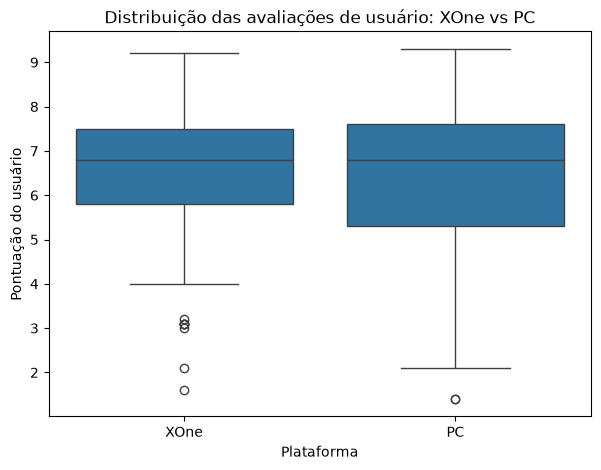

In [43]:
import matplotlib.pyplot as plt
import seaborn as sns

xbox_scores = games_recent[games_recent['platform'] == 'XOne']['user_score'].dropna()
pc_scores = games_recent[games_recent['platform'] == 'PC']['user_score'].dropna()


dados_grafico = pd.DataFrame({
    'user_score': pd.concat([xbox_scores, pc_scores]),
    'platform': ['XOne'] * len(xbox_scores) + ['PC'] * len(pc_scores)
})

plt.figure(figsize=(7,5))
sns.boxplot(data=dados_grafico, x='platform', y='user_score')
plt.title('Distribuição das avaliações de usuário: XOne vs PC')
plt.ylabel('Pontuação do usuário')
plt.xlabel('Plataforma')
plt.show()

In [44]:
from scipy import stats

alpha = 0.05

# 1. Testar se as variâncias são iguais
levene_result = stats.levene(xbox_scores, pc_scores)
print(f'p-valor do teste de Levene: {levene_result.pvalue:.6f}')

# 2. Decidir qual versão do teste t usar, com base no resultado do Levene
usar_variancias_iguais = levene_result.pvalue > alpha

# 3. Rodar o teste t com a decisão correta
resultado = stats.ttest_ind(xbox_scores, pc_scores, equal_var=usar_variancias_iguais)

print(f'p-valor do teste t: {resultado.pvalue:.4f}')

if resultado.pvalue < alpha:
    print('Rejeitamos H0: há diferença estatisticamente significativa')
else:
    print('Não rejeitamos H0: não há evidência suficiente de diferença')

p-valor do teste de Levene: 0.003898
p-valor do teste t: 0.1476
Não rejeitamos H0: não há evidência suficiente de diferença


**As classificações médias dos usuários das plataformas Xbox One e PC são as mesmas?**
O teste de Levene indicou diferença significativa nas variâncias entre os grupos (p-valor < 0.05), sendo utilizado o teste t de Welch (`equal_var=False`), que não assume variâncias iguais.
Segundo as comparações de médias do teste t, o valor p obtido (0.146) foi maior que o nível de significância adotado (0.05), portanto não há evidência estatística suficiente para rejeitar a hipótese nula. com base nos dados analisados, não foi possível identificar uma diferença estatisticamente significativa entre as classificações médias de usuários das plataformas Xbox One e PC.

#### As classificações médias de usuários para os gêneros Action (ação) e Sports (esportes) são diferentes?
Aqui, vamos testar se há diferenças nas classificações de usuários entre os gêneros Action (ação) e Sports (esportes). Nossa hipótese é que as classificações médias dos usuários para os gêneros Action (ação) e Sports (esportes) diferem entre si. Assim como no teste acima,primeiro vamos visualizar a distribuição das notas e depois vamos fazer o teste.
Pra o teste t, a hipótese nula é que as médias são iguais, e a hipótese alternativa é que as médias são diferentes.

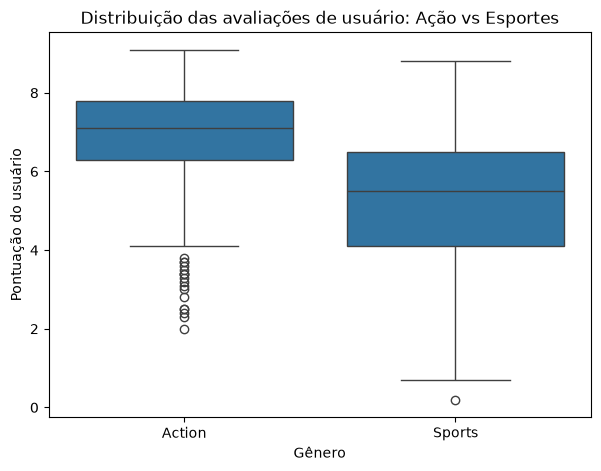

In [45]:
import matplotlib.pyplot as plt
import seaborn as sns

action_scores = games_recent[games_recent['genre'] == 'Action']['user_score'].dropna()
sports_scores = games_recent[games_recent['genre'] == 'Sports']['user_score'].dropna()


dados_grafico = pd.DataFrame({
    'user_score': pd.concat([action_scores, sports_scores]),
    'genre': ['Action'] * len(action_scores) + ['Sports'] * len(sports_scores)
})

plt.figure(figsize=(7,5))
sns.boxplot(data=dados_grafico, x='genre', y='user_score')
plt.title('Distribuição das avaliações de usuário: Ação vs Esportes')
plt.ylabel('Pontuação do usuário')
plt.xlabel('Gênero')
plt.show()

In [46]:
from scipy import stats

alpha = 0.05

# 1. Testar se as variâncias são iguais
levene_result = stats.levene(action_scores, sports_scores)
print(f'p-valor do teste de Levene: {levene_result.pvalue:.6f}')

# 2. Decidir qual versão do teste t usar, com base no resultado do Levene
usar_variancias_iguais = levene_result.pvalue > alpha

# 3. Rodar o teste t com a decisão correta
resultado = stats.ttest_ind(action_scores, sports_scores, equal_var=usar_variancias_iguais)

print(f'p-valor do teste t: {resultado.pvalue:.2e}') #notação científica, ex: 1.23e-15

if resultado.pvalue < alpha:
    print('Rejeitamos H0: há diferença estatisticamente significativa')
else:
    print('Não rejeitamos H0: não há evidência suficiente de diferença')

p-valor do teste de Levene: 0.000000
p-valor do teste t: 1.45e-20
Rejeitamos H0: há diferença estatisticamente significativa


 **As classificações médias de usuários para os gêneros Action (ação) e Sports (esportes) são diferentes?**
 O teste de Levene indicou diferença estatisticamente significativa nas variâncias entre os grupos (p-valor ≈ 0.000000), portanto foi utilizado o teste t de Welch (`equal_var=False`), que não assume variâncias iguais entre as amostras.
De acordo comas comparações feitas pelo teste t o resultado foi de um p-valor de 1.45e-20, oq ue é extremamente inferior ao nível de significância de 0.05. Com esse baixo valor, rejeitamos da hipótese nula de que as médias são iguais. Há evidência estatística muito forte de que as classificações médias de usuários diferem entre os gêneros "Action" e "Sports". O tamanho da amostra (centenas de jogos em cada gênero) contribui para essa alta significância estatística, tornando o teste sensível mesmo a diferenças moderadas entre as médias dos grupos.

## Etapa 6. Escreva uma conclusão geral

O objetivo geral do projeto foi identificar padrões que determinam o sucesso de um jogo, para subsidiar o planejamento da campanha publicitária de 2017 da loja Ice.

**Sobre a qualidade e preparação dos dados**

A base de dados apresentava diversos problemas típicos de fontes heterogêneas: inconsistências de formatação, tipos de dados incorretos, valores ausentes concentrados em colunas de avaliação (`critic_score`, `user_score`, `rating`) e ao menos um erro grave de registro (ano de lançamento incompatível com a plataforma). Esses problemas foram tratados de forma criteriosa, priorizando a preservação máxima de informação, e apenas descartando dados quando estritamente necessário para a integridade das análises.

**Sobre o período e as plataformas relevantes**

A análise do ciclo de vida das plataformas (mediana de 6 anos de atividade) e da transição de geração de consoles levou à definição de 2013 como marco inicial dos dados relevantes para  2017. Nesse período, a nova geração (PS4, XOne, WiiU) começou a substituir a  anterior (PS3, X360, Wii). Dentro desse período, o PS4 se consolidou como a plataforma líder e em crescimento, sendo a aposta mais segura para 2017. XOne mantém posição estável e secundária. As demais plataformas (PS3, X360, Wii, 3DS, WiiU, PC, PSV, PSP) mostram vendas em declínio ou irrelevantes no período mais recente.

**Sobre o que torna um jogo bem-sucedido**

Os dados mostram que o sucesso comercial de um jogo está mais associado à avaliação da crítica  especializada (correlação positiva moderada) do que à nota dos usuários  correlação praticamente nula) — um dado relevante para o timing de campanhas publicitárias, já que a  crítica se manifesta antes ou no lançamento, podendo influenciar a decisão de compra inicial,  enquanto a nota de usuários só existe depois da venda já ter ocorrido.

O teste de hipótese confirmou que as avaliações de usuários variam significativamente entre gêneros (Action vs Sports), mas não entre as plataformas testadas (XOne vs PC), sugerindo que o gênero do jogo é um fator mais determinante na percepção do público do que a plataforma em si.

Quanto a gênero, "Action" lidera em volume de vendas, mas isso reflete majoritariamente o alto número de lançamentos, não o desempenho individual dos títulos. "Shooter" é o gênero mais lucrativo por jogo lançado, representando uma aposta de maior retorno por título, ainda que com maior variabilidade de resultado (dependência de "blockbusters"). Adventure apresenta o padrão oposto: muitos lançamentos, mas desempenho consistentemente fraco.

**Sobre as diferenças regionais**

O perfil de consumo revela dois mercados distintos: América do Norte e Europa compartilham preferências semelhantes (consoles PS4/XOne/X360, gêneros Action/Shooter, rating M), enquanto o Japão apresenta um comportamento radicalmente diferente, dominado por plataformas portáteis (3DS) e pelo gênero Role-Playing, padrão que exige estratégias de marketing e portfólio de produtos específicas para esse mercado, em vez de uma campanha única e genérica para todas as regiões.

**Recomendações para a campanha de 2017**
1. Priorizar a plataforma PS4 como foco principal de investimento, por ser líder e estar em trajetória de crescimento no período mais recente analisado.
2. Considerar o gênero Shooter como aposta de maior retorno por título, e Action como aposta de volume (maior alcance, ainda que com retorno médio mais modesto por unidade).
3. Usar a avaliação da crítica especializada, não a nota dos usuários, como um indicador relevante de potencial de sucesso comercial ao selecionar jogos para promover.
4. Segmentar a estratégia por região: campanhas para América do Norte e União Europeia podem seguir uma linha semelhante (foco em PS4/XOne, Action/Shooter), enquanto a campanha para o Japão deve ser adaptada, priorizando plataformas portáteis (3DS) e o gênero Role-Playing.